## Project - 1

In [81]:
import numpy as np
import matplotlib.pyplot as plt
import re

### Equilibration

In [82]:
# proteins = ['ala', 'arg', 'asp_ac', 'aspara', 'cys']
# base_dir = '/home/kiranr/Documents/3-2/PSCM/PROJECT-1'

In [83]:
# ============================================================
# EXTENDED ANALYSIS — Cell 0: Full protein list + metadata
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy import stats
from scipy.ndimage import gaussian_filter1d

# ── All 20 amino acids (update abbreviations to match your folder names) ──
proteins = [
    'alanine', 'arginine', 'aspartic_acid', 'asparagine', 'cysteine',
    'glutamine', 'glutamic_acid', 'glycine', 'histidine', 'isoleucine',
    'leucine', 'lysine', 'methionine', 'phenylalanine', 'proline',
    'serine', 'threonine', 'tryptophan', 'tyrosine', 'valine'
]

# proteins = [
#     'alanine', 'arginine', 'aspartic_acid', 'asparagine', 'cysteine',
#     'glutamine', 'glycine', 'histidine', 'isoleucine',
#     'leucine', 'methionine', 'phenylalanine', 'proline',
#     'serine', 'threonine', 'tryptophan', 'tyrosine'
# ]

# ── Physicochemical groups ──
groups = {
    'Nonpolar':          ['alanine', 'glycine', 'valine', 'leucine', 'isoleucine', 'proline', 'phenylalanine', 'methionine', 'tryptophan'],
    'Polar uncharged':   ['serine', 'threonine', 'cysteine', 'tyrosine', 'asparagine', 'glutamine'],
    'Positively charged':['arginine', 'lysine', 'histidine'],
    'Negatively charged':['aspartic_acid', 'glutamic_acid'],
}

# ── Physicochemical groups ──
# groups = {
#     'Nonpolar':          ['alanine', 'glycine', 'leucine', 'isoleucine', 'proline', 'phenylalanine', 'methionine', 'tryptophan'],
#     'Polar uncharged':   ['serine', 'threonine', 'cysteine', 'tyrosine', 'asparagine', 'glutamine'],
#     'Positively charged':['arginine', 'histidine'],
#     'Negatively charged':['aspartic_acid'],
# }

# Color per group (used throughout)
group_colors = {
    'Nonpolar':           '#e69f00',
    'Polar uncharged':    '#56b4e9',
    'Positively charged': '#009e73',
    'Negatively charged': '#d55e00',
}

def get_group(protein):
    for g, members in groups.items():
        if protein in members:
            return g
    return 'Unknown'

# ── Kyte-Doolittle hydrophobicity, MW, side-chain volume, net charge, H-bond donors ──
aa_properties = {
    #           hydrophob   MW(Da)  SC_vol(Å³)  charge  HBD
    'alanine':    ( 1.8,        89.1,   67,          0,      0 ),
    'arginine':    (-4.5,       174.2,  148,         +1,      5 ),
    'aspartic_acid': (-3.5,       133.1,   91,         -1,      1 ),
    'asparagine': (-3.5,       132.1,   96,          0,      2 ),
    'cysteine':    ( 2.5,       121.2,   86,          0,      1 ),
    'glutamine':    (-3.5,       146.2,  114,          0,      2 ),
    'glutamic_acid':    (-3.5,       147.1,  109,         -1,      1 ),
    'glycine':    (-0.4,        75.0,   48,          0,      0 ),
    'histidine':    (-3.2,       155.2,  118,         +0.1,    2 ),
    'isoleucine':    ( 4.5,       131.2,  124,          0,      0 ),
    'leucine':    ( 3.8,       131.2,  124,          0,      0 ),
    'lysine':    (-3.9,       146.2,  135,         +1,      3 ),
    'methionine':    ( 1.9,       149.2,  124,          0,      0 ),
    'phenylalanine':    ( 2.8,       165.2,  135,          0,      0 ),
    'proline':    (-1.6,       115.1,   90,          0,      0 ),
    'serine':    (-0.8,       105.1,   73,          0,      1 ),
    'threonine':    (-0.7,       119.1,   93,          0,      1 ),
    'tryptophan':    (-0.9,       204.2,  163,          0,      1 ),
    'tyrosine':    (-1.3,       181.2,  141,          0,      2 ),
    'valine':    ( 4.2,       117.1,  105,          0,      0 ),
}

base_dir = '/home/kiranr/Documents/3-2/PSCM/PROJECT-1'
n_traj   = 10
dt       = 0.1
v        = 0.01
k_B      = 1.987e-3
Temp     = 300
T        = k_B * Temp

print(f"Loaded {len(proteins)} amino acids across {len(groups)} groups.")
for g, members in groups.items():
    print(f"  {g}: {members}")

Loaded 20 amino acids across 4 groups.
  Nonpolar: ['alanine', 'glycine', 'valine', 'leucine', 'isoleucine', 'proline', 'phenylalanine', 'methionine', 'tryptophan']
  Polar uncharged: ['serine', 'threonine', 'cysteine', 'tyrosine', 'asparagine', 'glutamine']
  Positively charged: ['arginine', 'lysine', 'histidine']
  Negatively charged: ['aspartic_acid', 'glutamic_acid']


### SMD - Production

In [87]:
# # ============================================================
# # CELL 1 — Imports & config
# # ============================================================
# import re

# proteins  = ['ala', 'arg', 'asp_ac', 'aspara', 'cys']
# base_dir  = '/home/kiranr/Documents/3-2/PSCM/PROJECT-1'
# n_traj    = 10          # trajectories per protein

# # SMD parameters (from smd.tcl + smd.namd)
# dt        = 0.1         # ps  (Tclfreq=50 steps × 2 fs/step)
# v         = 0.01        # Å/ps  (0.00002 Å/step ÷ 0.002 ps/step)
# k_B       = 1.987e-3    # kcal mol⁻¹ K⁻¹
# Temp      = 300         # K
# T         = k_B * Temp  # kcal/mol  ≈ 0.596

In [88]:
# ============================================================
# CELL 2 — Parse c1z and c2z from smd.tcl
# ============================================================
def parse_constraints(protein):
    tcl_path = f"{base_dir}/{protein}/smd.tcl"
    c1z, c2z = None, None
    with open(tcl_path, 'r') as f:
        for line in f:
            m1 = re.match(r'\s*set\s+c1z\s+([-\d.]+)', line)
            m2 = re.match(r'\s*set\s+c2z\s+([-\d.]+)', line)
            if m1: c1z = float(m1.group(1))
            if m2: c2z = float(m2.group(1))
    if c1z is None or c2z is None:
        raise ValueError(f"Could not parse c1z/c2z from {tcl_path}")
    print(f"{protein}: c1z = {c1z}, c2z = {c2z}, initial separation = {c2z - c1z:.3f} Å")
    return c1z, c2z

In [89]:
for protein in proteins:
    c1z, c2z = parse_constraints(protein)
    # print(c1z, c2z)

alanine: c1z = -0.32, c2z = 14.68, initial separation = 15.000 Å
arginine: c1z = -0.4, c2z = 14.58, initial separation = 14.980 Å
aspartic_acid: c1z = -0.23, c2z = 29.71, initial separation = 29.940 Å
asparagine: c1z = -0.23, c2z = 30.18, initial separation = 30.410 Å
cysteine: c1z = -0.12, c2z = 10.73, initial separation = 10.850 Å
glutamine: c1z = 0.0, c2z = 30.321, initial separation = 30.321 Å
glutamic_acid: c1z = 2.444, c2z = 30.625, initial separation = 28.181 Å
glycine: c1z = 2.393, c2z = 33.951, initial separation = 31.558 Å
histidine: c1z = 0.0, c2z = 25.839, initial separation = 25.839 Å
isoleucine: c1z = -7.345, c2z = 7.013, initial separation = 14.358 Å
leucine: c1z = -7.378, c2z = 7.02, initial separation = 14.398 Å
lysine: c1z = 2.145, c2z = 29.602, initial separation = 27.457 Å
methionine: c1z = 0.0, c2z = 13.689, initial separation = 13.689 Å
phenylalanine: c1z = -8.127, c2z = 5.706, initial separation = 13.833 Å
proline: c1z = 0.0, c2z = 26.854, initial separation = 26

In [90]:
# ============================================================
# CELL 2 — Helper: load all trajectories for one protein
# ============================================================
def load_trajectories(protein, n_traj=10):
    """
    Returns arrays of shape (n_timesteps, n_traj):
      t_arr  – time (ps)
      z_arr  – z-coordinate of pulled atom (Å)
      f_arr  – z-force on pulled atom (kcal/mol/Å)
    """
    t_list, z_list, f_list = [], [], []

    for i in range(0, n_traj):
        fname = f"{base_dir}/{protein}/{protein}_smd_tcl_1{i}.out"
        data  = np.loadtxt(fname)          # columns: time, r1z, f1z
        t_list.append(data[:, 0])
        z_list.append(data[:, 1])
        f_list.append(data[:, 2])

    # Stack so columns = trajectories
    t_arr = np.column_stack(t_list)
    z_arr = np.column_stack(z_list)
    f_arr = np.column_stack(f_list)
    return t_arr, z_arr, f_arr

In [91]:
# ============================================================
# CELL 3 — Compute extension c and work W
# ============================================================
def compute_extension_and_work(t_arr, f_arr, c1z, c2z):
    """
    c  : constraint-point separation at each timestep (Å), shape (n_steps,)
    W  : cumulative work for each trajectory (kcal/mol), shape (n_steps, n_traj)

    The moving constraint starts at c1z_init and moves at speed -v (pulled inward).
    Extension = distance between c2 (fixed) and c1 (moving):
      c(t) = c2z_init - (c1z_init - v*t)  =  (c2z_init - c1z_init) + v*t
    """
    t_vec = t_arr[:, 0]                          # 1-D time vector
    c     = (c2z - c1z) + v * t_vec    # shape (n_steps,)

    # Work = v·dt·cumsum(F)  — same formula as the tutorial
    # f_arr is in kcal/mol/Å, v in Å/ps, dt in ps → W in kcal/mol
    W = v * dt * np.cumsum(-f_arr, axis=0)

    return c, W

In [92]:
# # ============================================================
# # CELL 4 — PMF estimators (Jarzynski)
# # ============================================================
# def compute_pmf(W, T):
#     """
#     Three PMF estimates from Jarzynski's equality.
#     W shape: (n_steps, n_traj)
#     Returns 1-D arrays of length n_steps.
#     """
#     Fexp = -T * np.log(np.mean(np.exp(-W / T), axis=1))   # exponential average
#     F1   = np.mean(W, axis=1)                               # 1st-order cumulant (avg work)
#     F2   = (np.mean(W, axis=1)
#             - 1/(2*T) * (np.mean(W**2, axis=1) - np.mean(W, axis=1)**2))  # 2nd-order
#     return Fexp, F1, F2

def compute_pmf(W, T):
    # Numerically stable exponential average using log-sum-exp trick
    exponent  = -W / T                                        # shape (n_steps, n_traj)
    max_exp   = np.max(exponent, axis=1, keepdims=True)       # per-timestep max for stability
    Fexp      = -T * (np.log(np.mean(np.exp(exponent - max_exp), axis=1)) + max_exp.squeeze())

    F1 = np.mean(W, axis=1)
    F2 = np.mean(W, axis=1) - 1/(2*T) * (np.mean(W**2, axis=1) - np.mean(W, axis=1)**2)
    return Fexp, F1, F2

alanine: c1z = -0.32, c2z = 14.68, initial separation = 15.000 Å


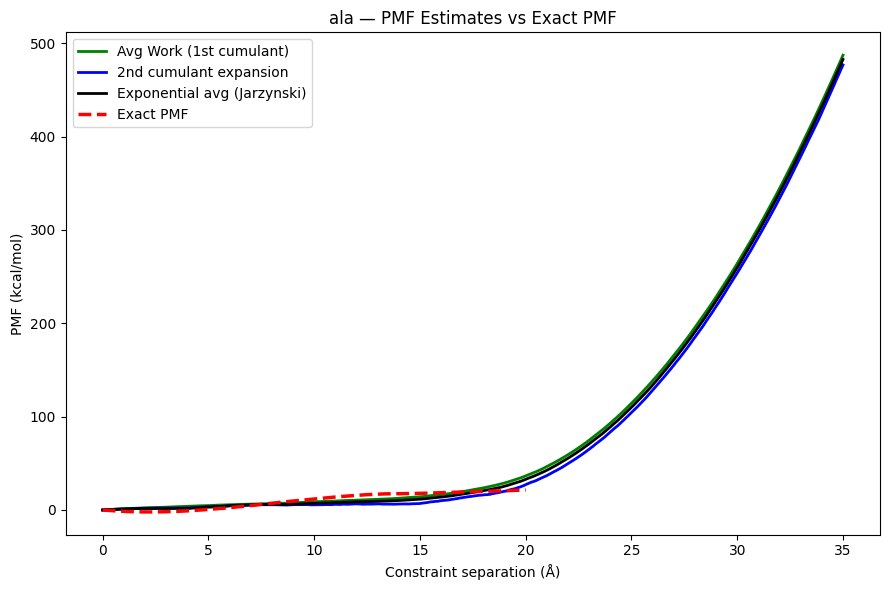

In [93]:
# ============================================================
# Alanine PMF vs Exact (from da.mat)
# ============================================================
from scipy.io import loadmat

# Load da.mat
mat = loadmat(f"{base_dir}/da.mat")
Fexact = mat['Fexact']   # shape (n_points, 2): col0 = extension, col1 = PMF

# Get alanine PMF estimates (already computed in the main loop, but redo here cleanly)
c1z, c2z            = parse_constraints('alanine')
t_arr, z_arr, f_arr = load_trajectories('alanine', n_traj)
c, W                = compute_extension_and_work(t_arr, f_arr, c1z, c2z)
c=c+c1z-c2z  # Shift so c=0 at start of pulling
Fexp, F1, F2        = compute_pmf(W, T)

# Plot
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(c,              F1,            color='green', lw=2,   label='Avg Work (1st cumulant)')
ax.plot(c,              F2,            color='blue',  lw=2,   label='2nd cumulant expansion')
ax.plot(c,              Fexp,          color='black', lw=2,   label='Exponential avg (Jarzynski)')
ax.plot(Fexact[:, 0]-13,  Fexact[:, 1],  color='red',   lw=2.5, label='Exact PMF', linestyle='--')

ax.set_xlabel("Constraint separation (Å)")
ax.set_ylabel("PMF (kcal/mol)")
ax.set_title("ala — PMF Estimates vs Exact PMF")
ax.legend()
plt.tight_layout()
# plt.savefig(f"{base_dir}/ala/ala_pmf_vs_exact.png", dpi=150)
plt.show()

In [94]:
# ── Master results dict ──
results = {}

for protein in proteins:
    print(f"Processing {protein}...", end=' ')
    try:
        c1z, c2z            = parse_constraints(protein)
        t_arr, z_arr, f_arr = load_trajectories(protein, n_traj)
        c, W                = compute_extension_and_work(t_arr, f_arr, c1z, c2z)
        c_shifted           = c + c1z - c2z          # starts at 0
        Fexp, F1, F2        = compute_pmf(W, T)

        # ── Scalar summaries ──
        W_final   = W[-1, :]                          # final work per trajectory
        mean_W    = float(np.mean(W_final))
        std_W     = float(np.std(W_final))
        delta_F   = float(F2[-1] - F2[0])            # PMF barrier height (2nd cumulant)
        W_diss    = mean_W - delta_F                  # dissipated work

        # Peak force per trajectory (rupture force)
        peak_F    = np.max(np.abs(f_arr), axis=0)    # shape (n_traj,)
        mean_rupF = float(np.mean(peak_F))
        std_rupF  = float(np.std(peak_F))

        # PMF barrier position (x‡): where F2 is maximum
        barrier_idx = int(np.argmax(F2))
        x_barrier   = float(c_shifted[barrier_idx])

        results[protein] = {
            'c':          c_shifted,
            'W':          W,
            'F1':         F1,  'F2': F2,  'Fexp': Fexp,
            'W_final':    W_final,
            'mean_W':     mean_W,    'std_W':     std_W,
            'delta_F':    delta_F,
            'W_diss':     W_diss,
            'mean_rupF':  mean_rupF, 'std_rupF':  std_rupF,
            'x_barrier':  x_barrier,
            'z_arr':      z_arr,     'f_arr':     f_arr,
            't_arr':      t_arr,
        }
        # print("✓")
    except Exception as e:
        print(f"ERROR: {e}")

print(f"\nDone. {len(results)}/{len(proteins)} amino acids loaded.")

Processing alanine... alanine: c1z = -0.32, c2z = 14.68, initial separation = 15.000 Å
Processing arginine... arginine: c1z = -0.4, c2z = 14.58, initial separation = 14.980 Å
Processing aspartic_acid... aspartic_acid: c1z = -0.23, c2z = 29.71, initial separation = 29.940 Å
Processing asparagine... asparagine: c1z = -0.23, c2z = 30.18, initial separation = 30.410 Å
Processing cysteine... cysteine: c1z = -0.12, c2z = 10.73, initial separation = 10.850 Å
Processing glutamine... glutamine: c1z = 0.0, c2z = 30.321, initial separation = 30.321 Å
Processing glutamic_acid... glutamic_acid: c1z = 2.444, c2z = 30.625, initial separation = 28.181 Å
Processing glycine... glycine: c1z = 2.393, c2z = 33.951, initial separation = 31.558 Å
Processing histidine... histidine: c1z = 0.0, c2z = 25.839, initial separation = 25.839 Å
Processing isoleucine... isoleucine: c1z = -7.345, c2z = 7.013, initial separation = 14.358 Å
Processing leucine... leucine: c1z = -7.378, c2z = 7.02, initial separation = 14.3


Protein: alanine
alanine: c1z = -0.32, c2z = 14.68, initial separation = 15.000 Å


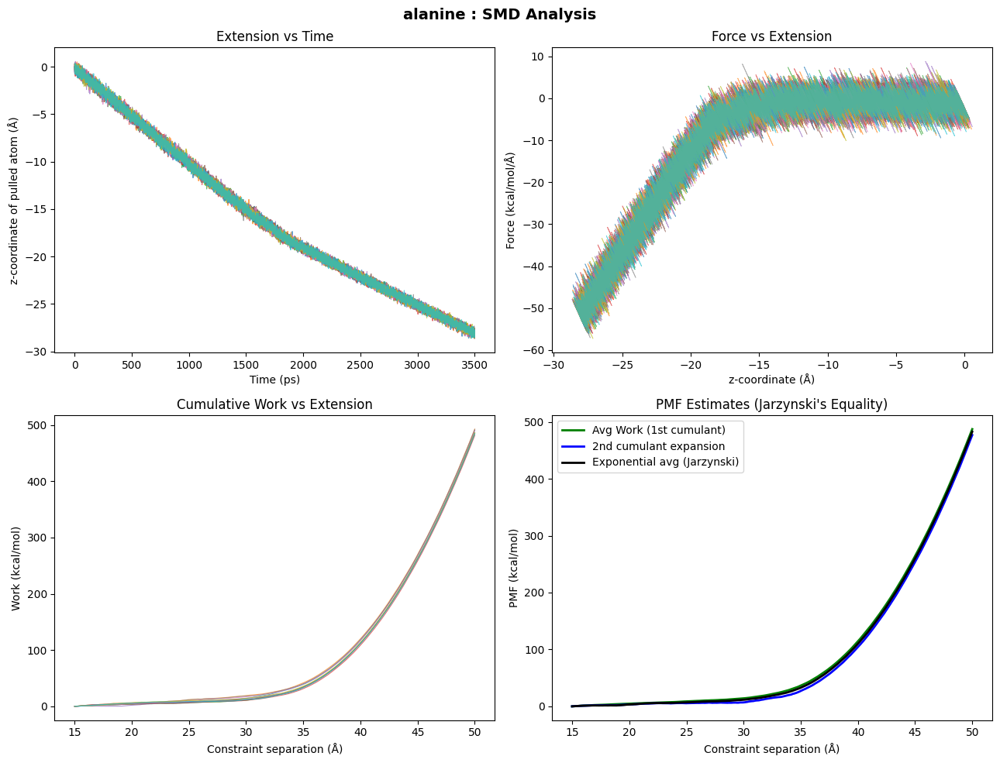


Protein: arginine
arginine: c1z = -0.4, c2z = 14.58, initial separation = 14.980 Å


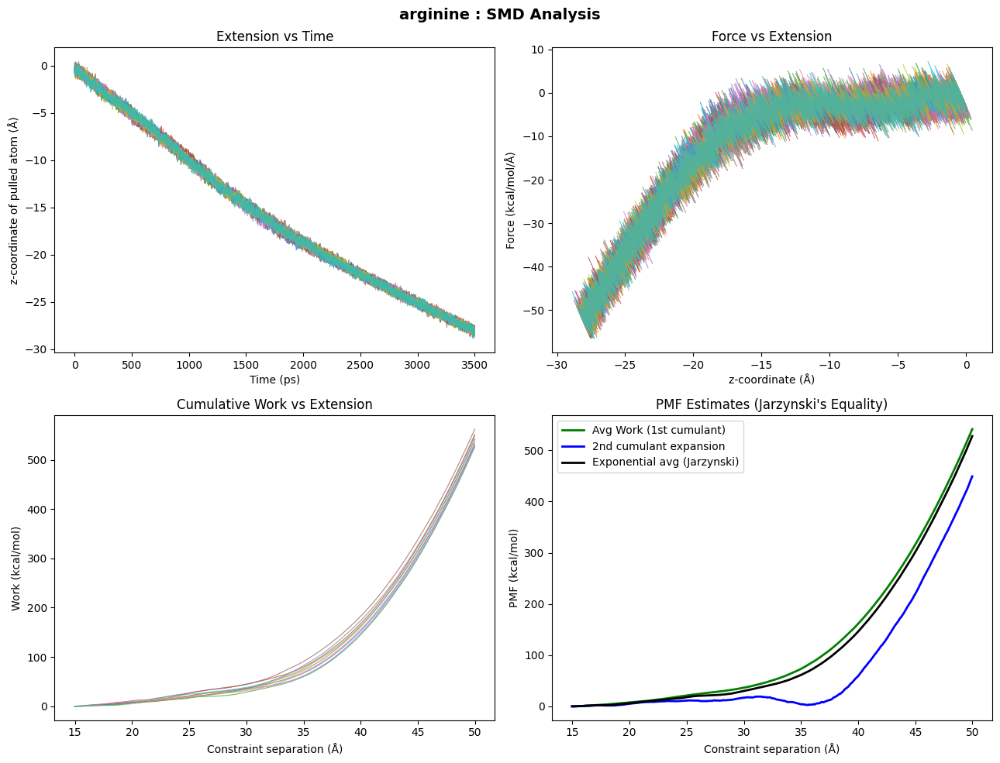


Protein: aspartic_acid
aspartic_acid: c1z = -0.23, c2z = 29.71, initial separation = 29.940 Å


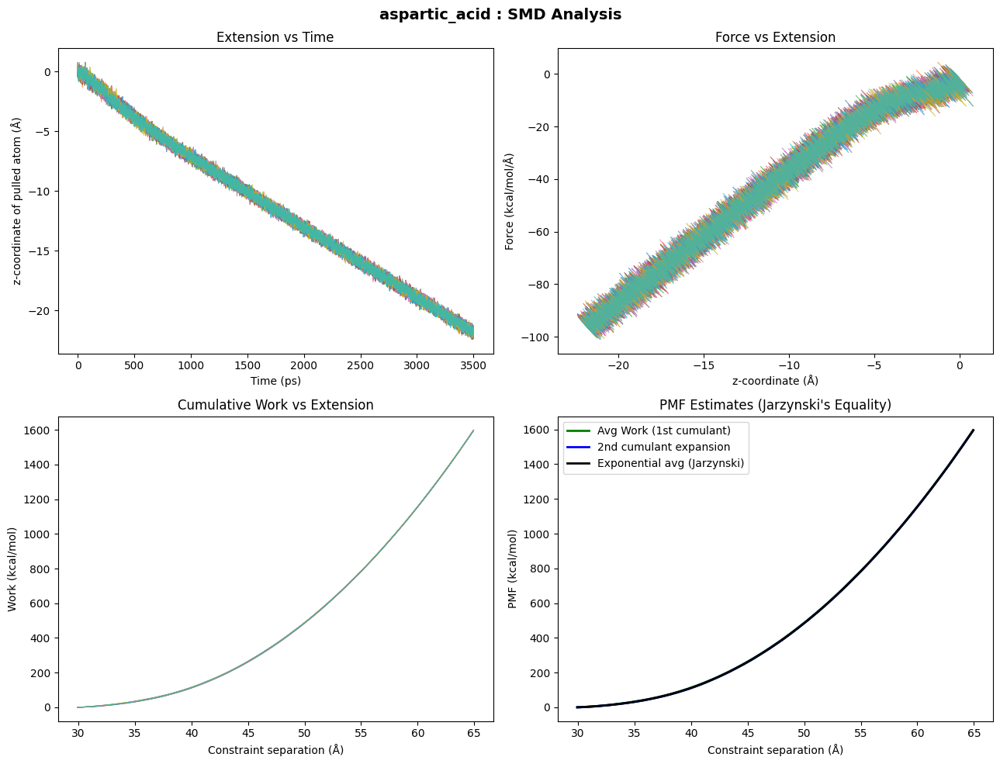


Protein: asparagine
asparagine: c1z = -0.23, c2z = 30.18, initial separation = 30.410 Å


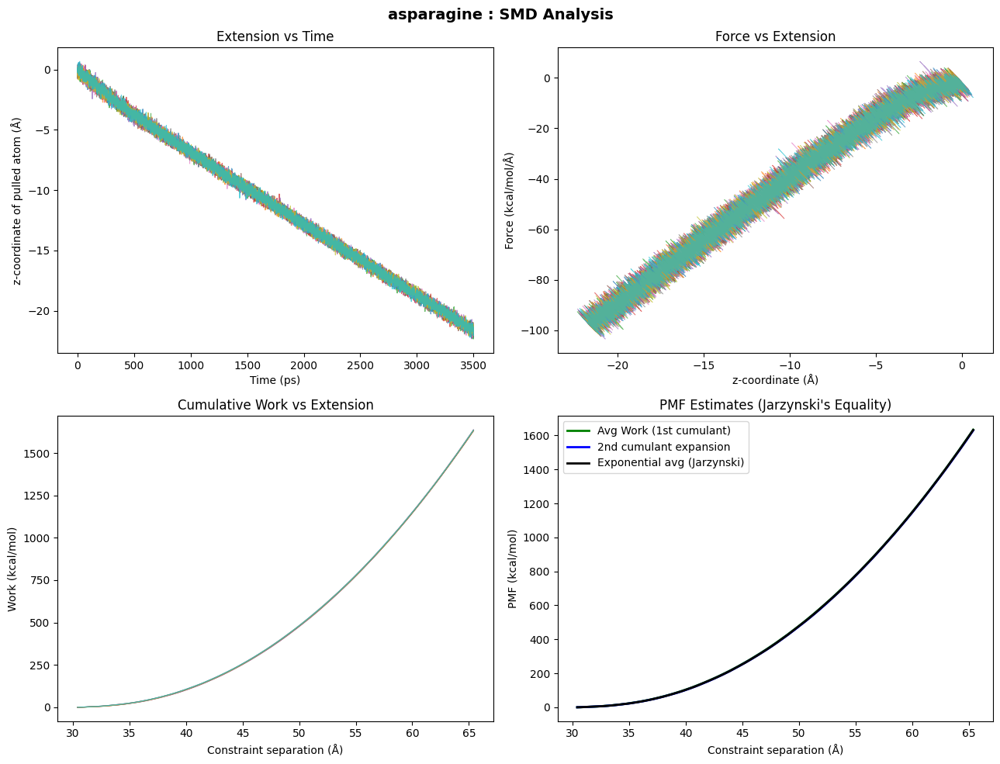


Protein: cysteine
cysteine: c1z = -0.12, c2z = 10.73, initial separation = 10.850 Å


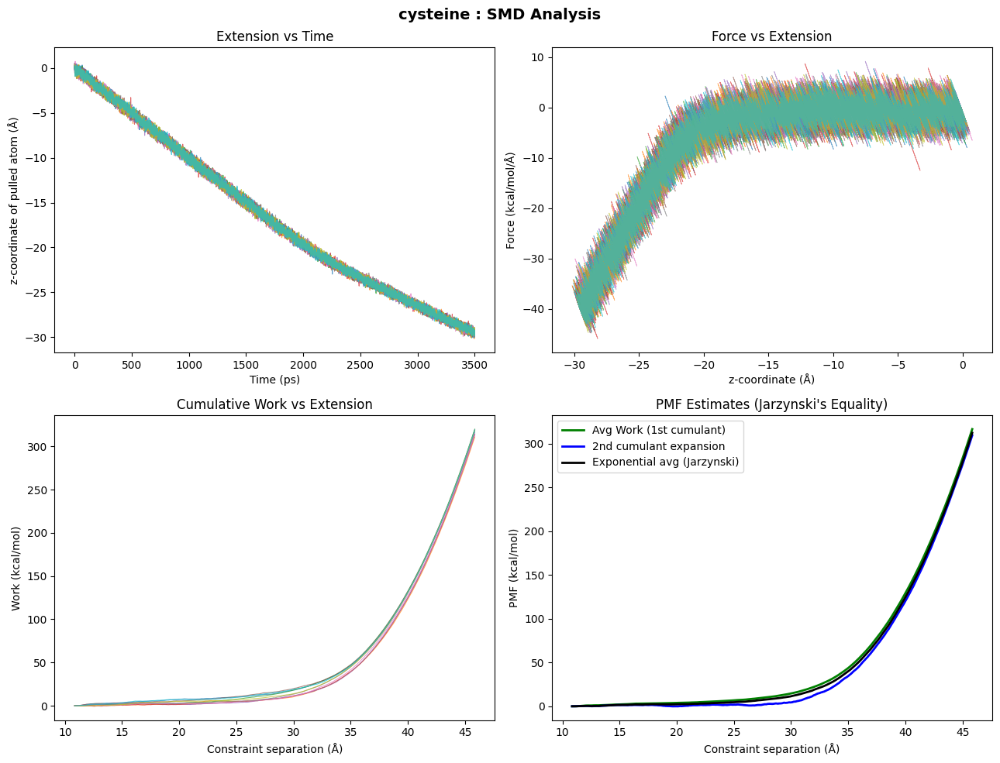


Protein: glutamine
glutamine: c1z = 0.0, c2z = 30.321, initial separation = 30.321 Å


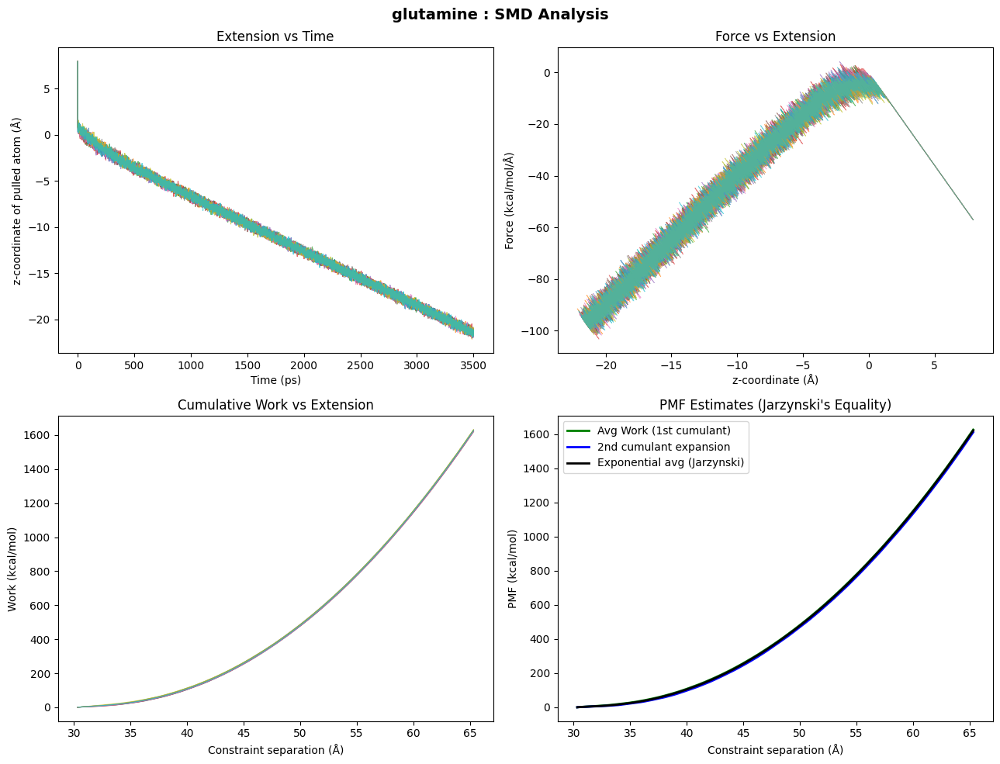


Protein: glutamic_acid
glutamic_acid: c1z = 2.444, c2z = 30.625, initial separation = 28.181 Å


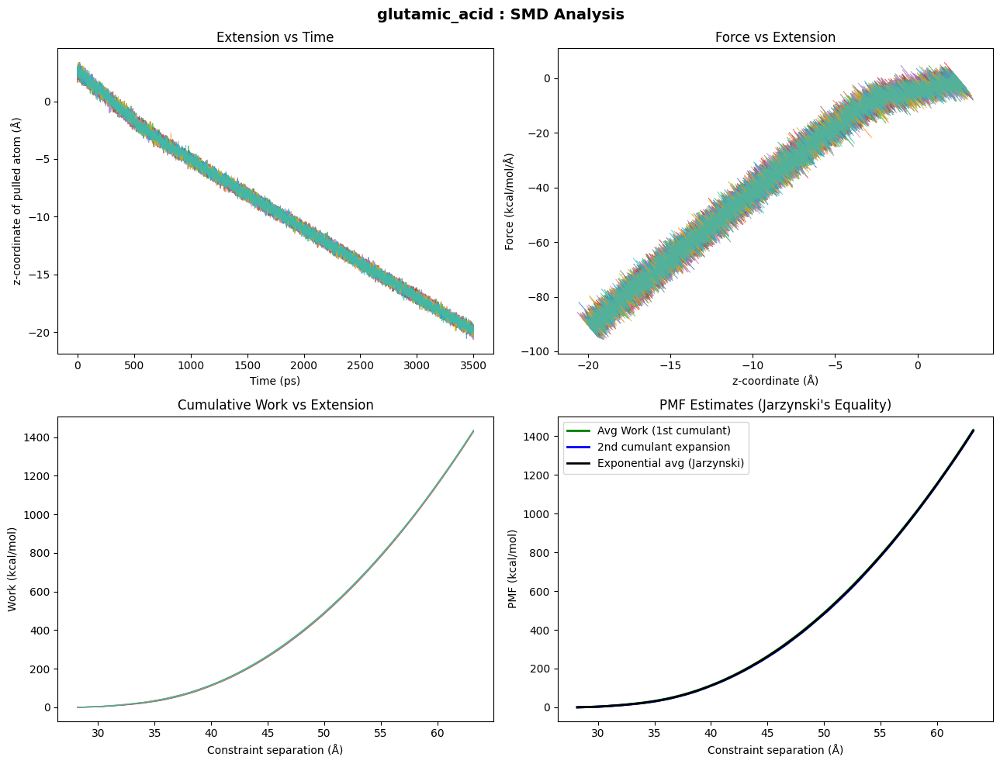


Protein: glycine
glycine: c1z = 2.393, c2z = 33.951, initial separation = 31.558 Å


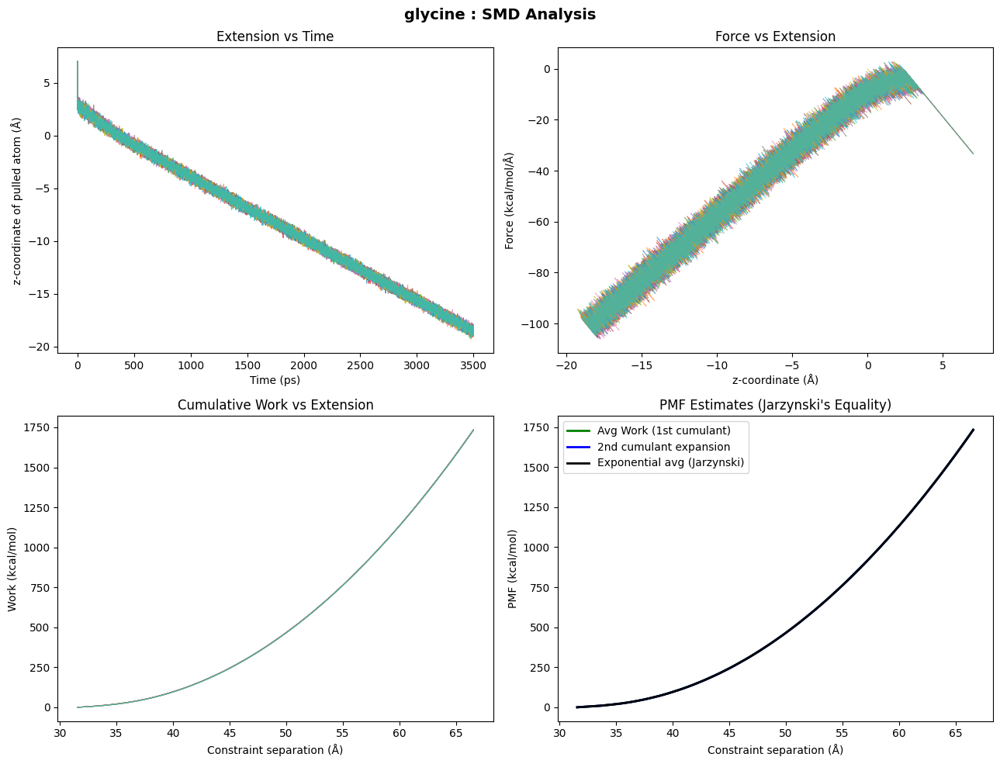


Protein: histidine
histidine: c1z = 0.0, c2z = 25.839, initial separation = 25.839 Å


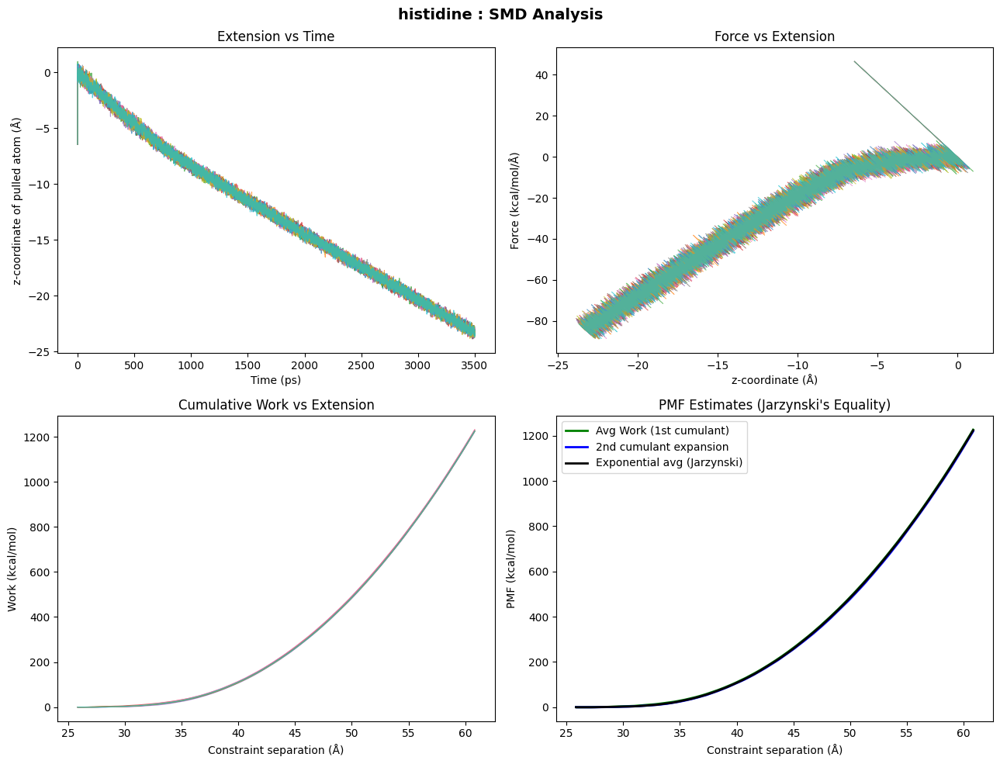


Protein: isoleucine
isoleucine: c1z = -7.345, c2z = 7.013, initial separation = 14.358 Å


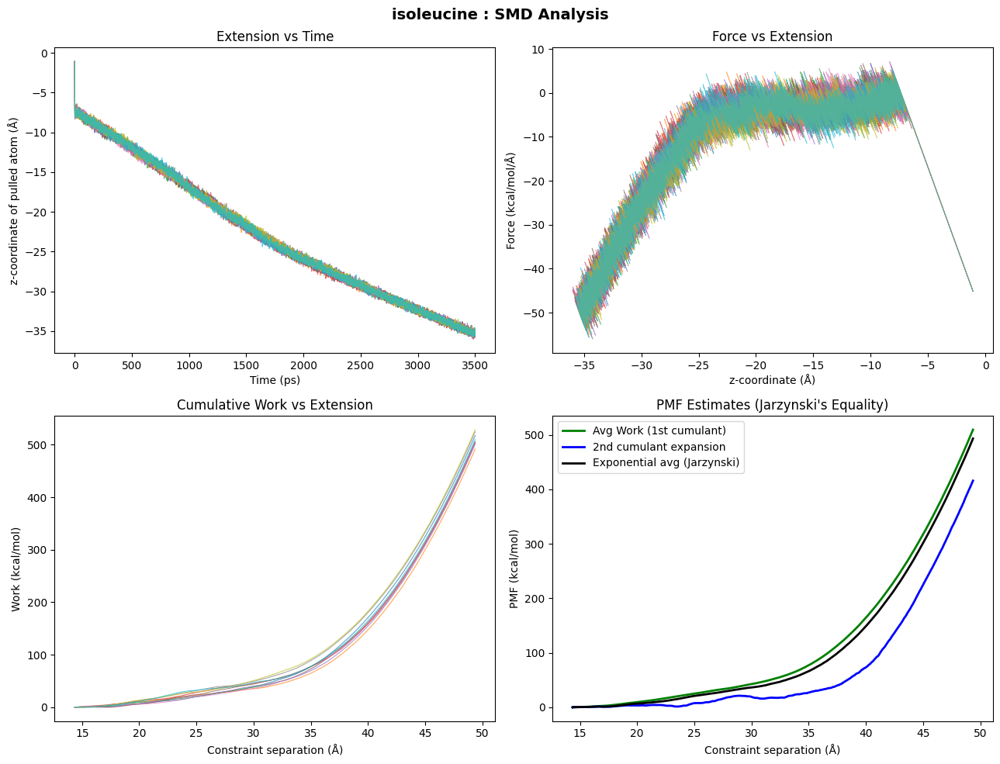


Protein: leucine
leucine: c1z = -7.378, c2z = 7.02, initial separation = 14.398 Å


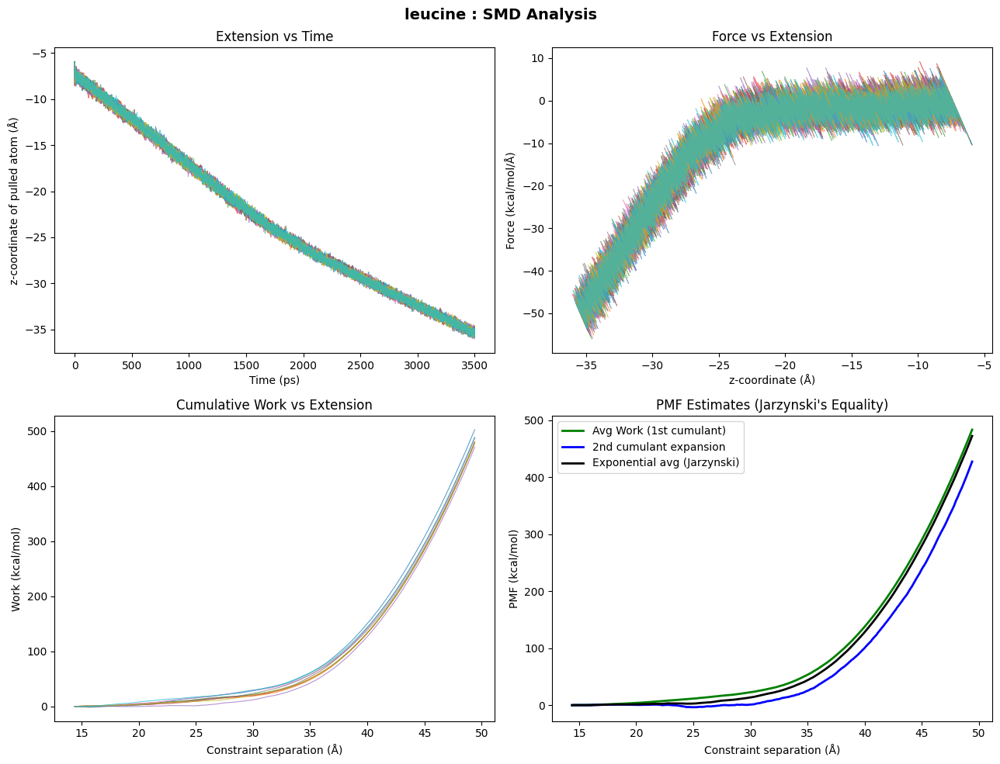


Protein: lysine
lysine: c1z = 2.145, c2z = 29.602, initial separation = 27.457 Å


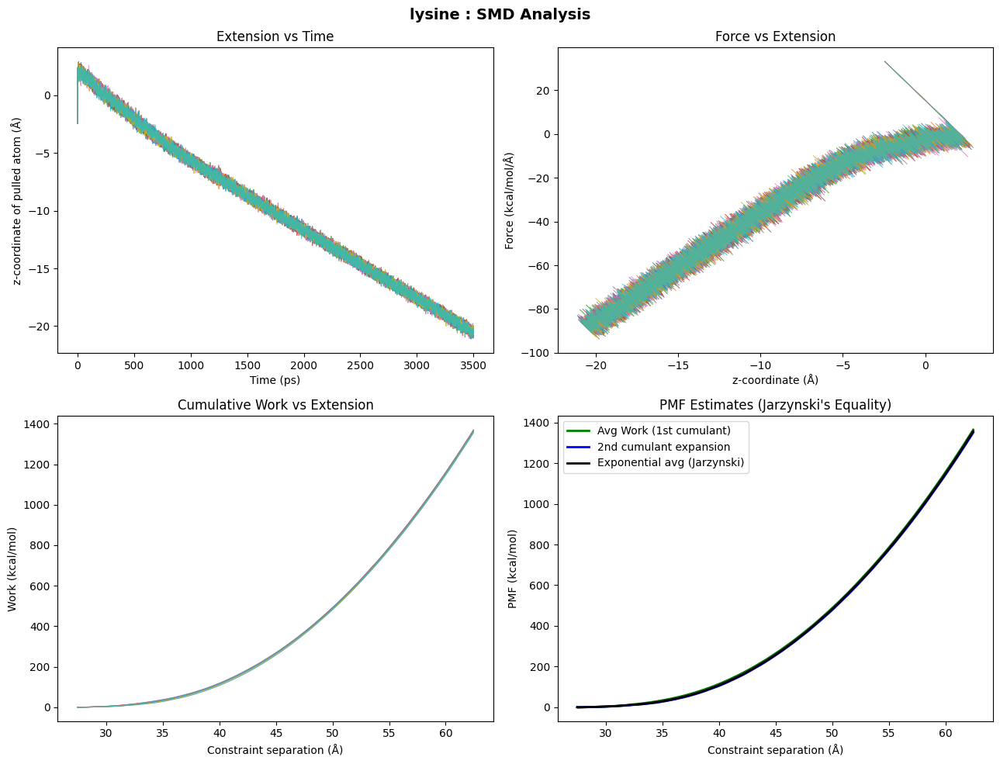


Protein: methionine
methionine: c1z = 0.0, c2z = 13.689, initial separation = 13.689 Å


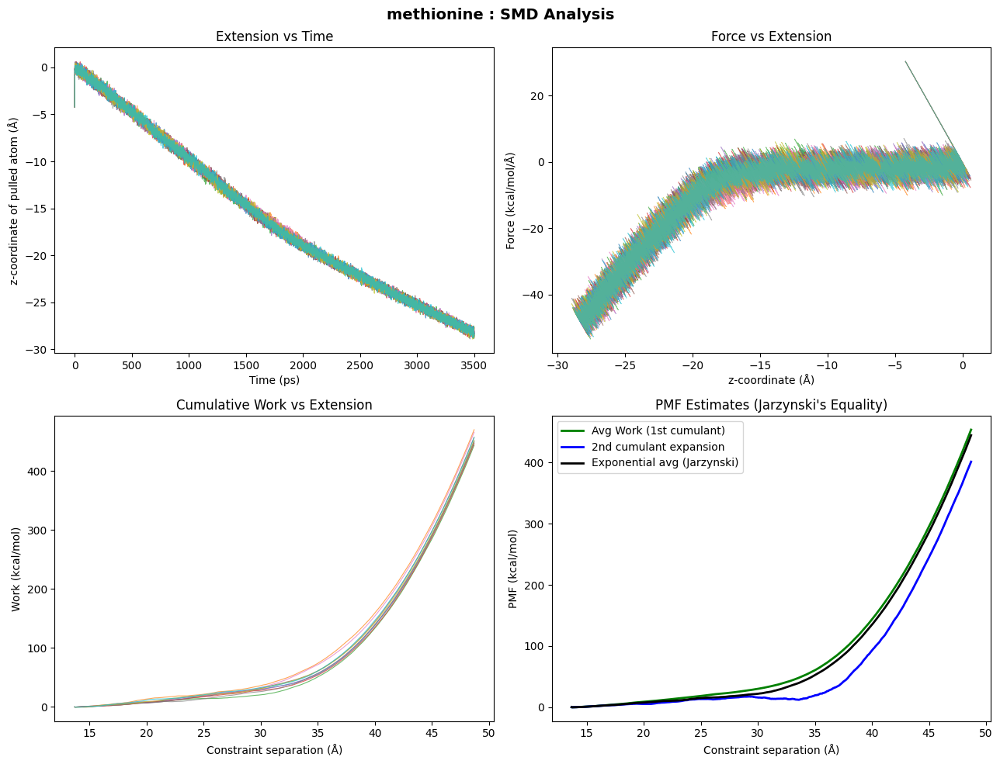


Protein: phenylalanine
phenylalanine: c1z = -8.127, c2z = 5.706, initial separation = 13.833 Å


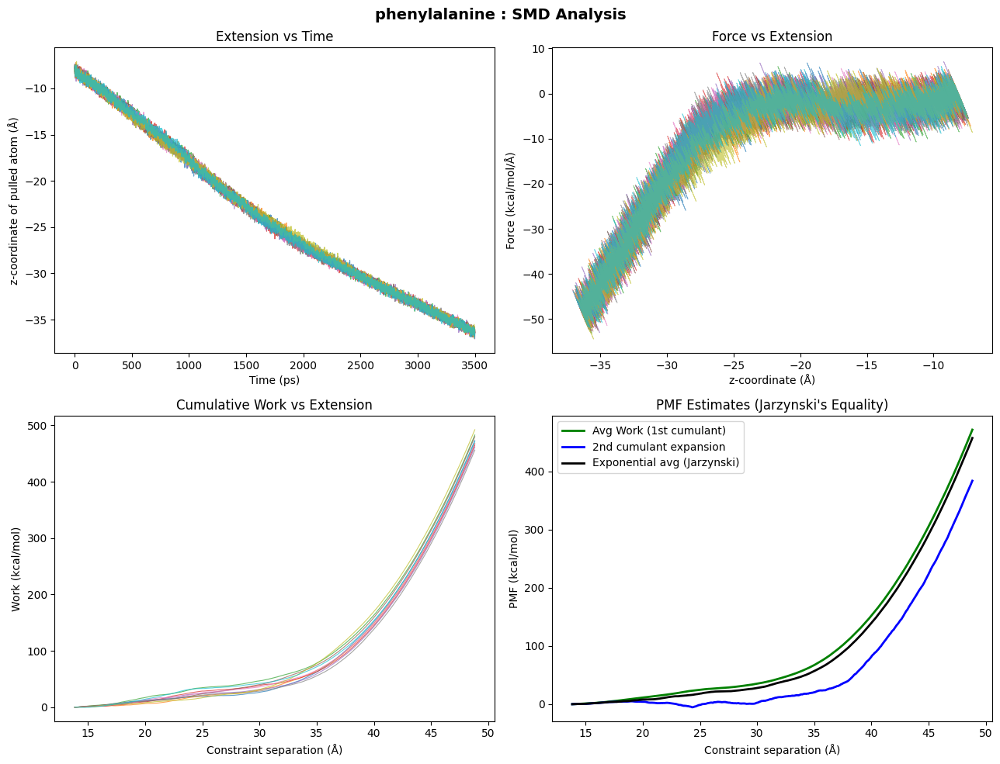


Protein: proline
proline: c1z = 0.0, c2z = 26.854, initial separation = 26.854 Å


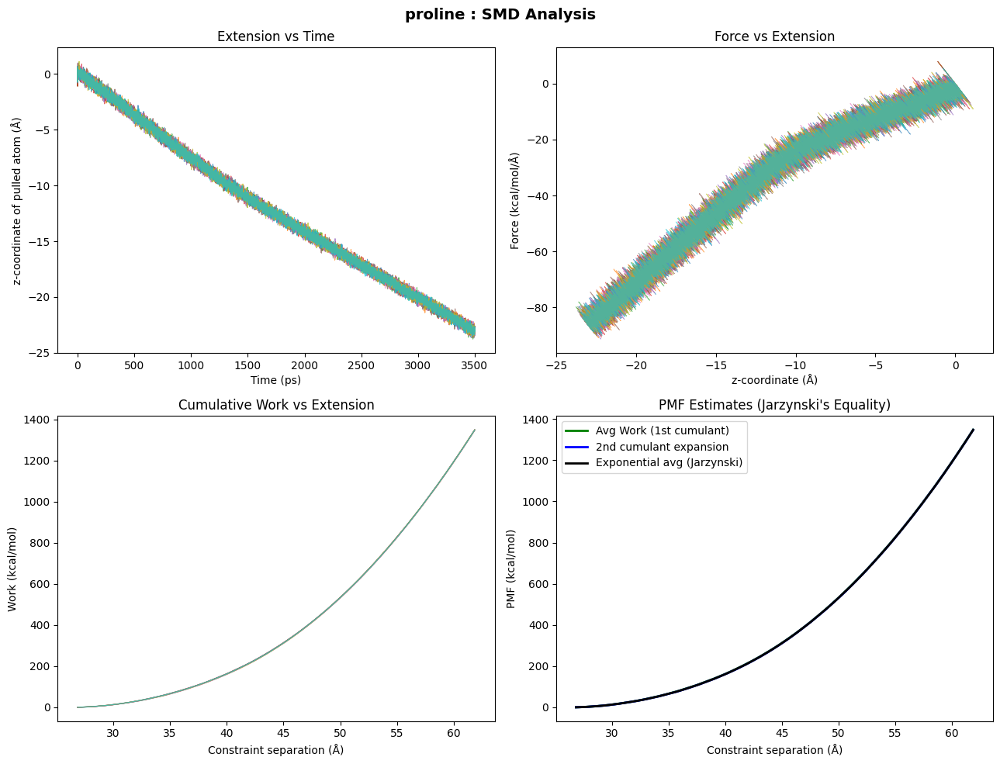


Protein: serine
serine: c1z = 2.435, c2z = 33.792, initial separation = 31.357 Å


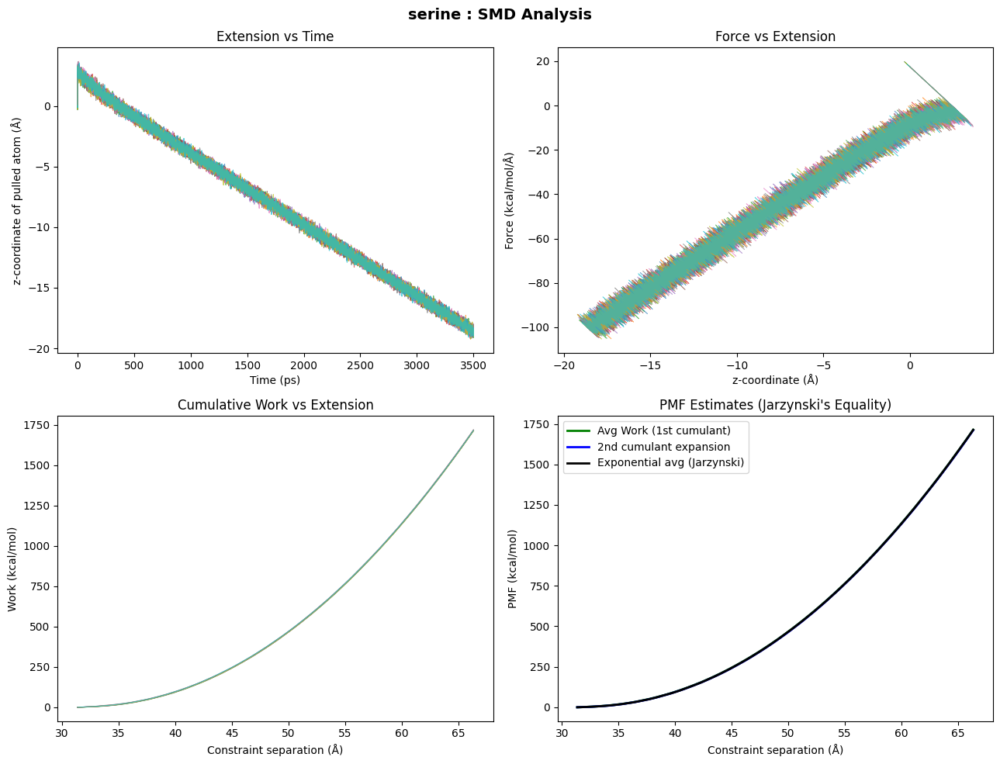


Protein: threonine
threonine: c1z = -14.589, c2z = 14.554, initial separation = 29.143 Å


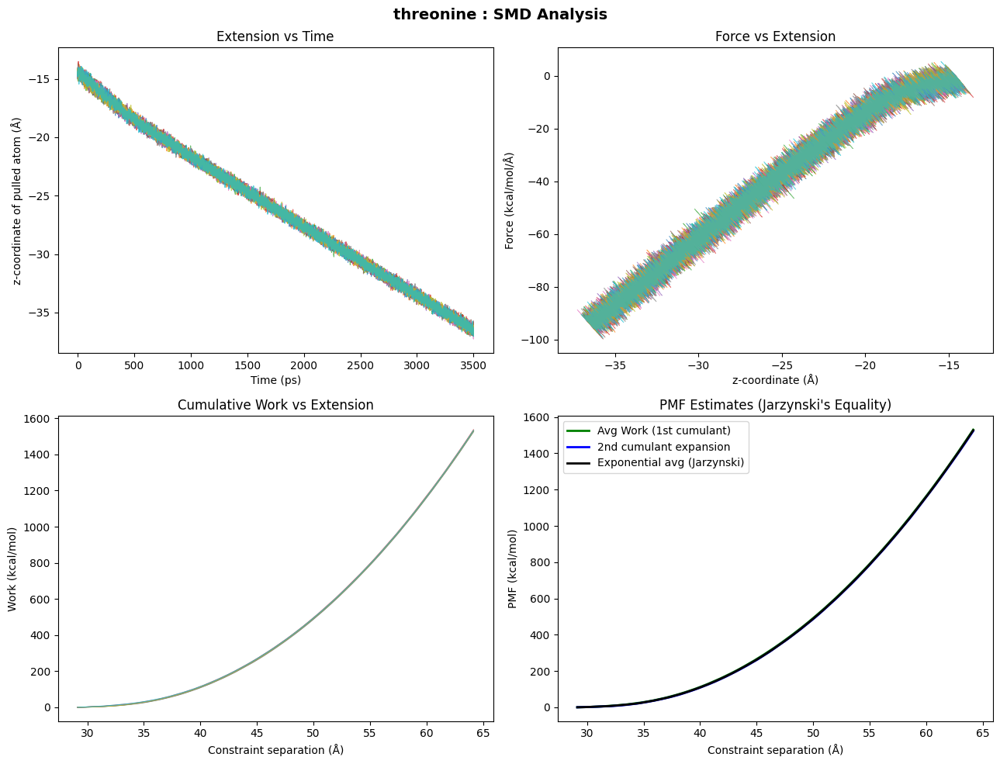


Protein: tryptophan
tryptophan: c1z = -11.366, c2z = 9.483, initial separation = 20.849 Å


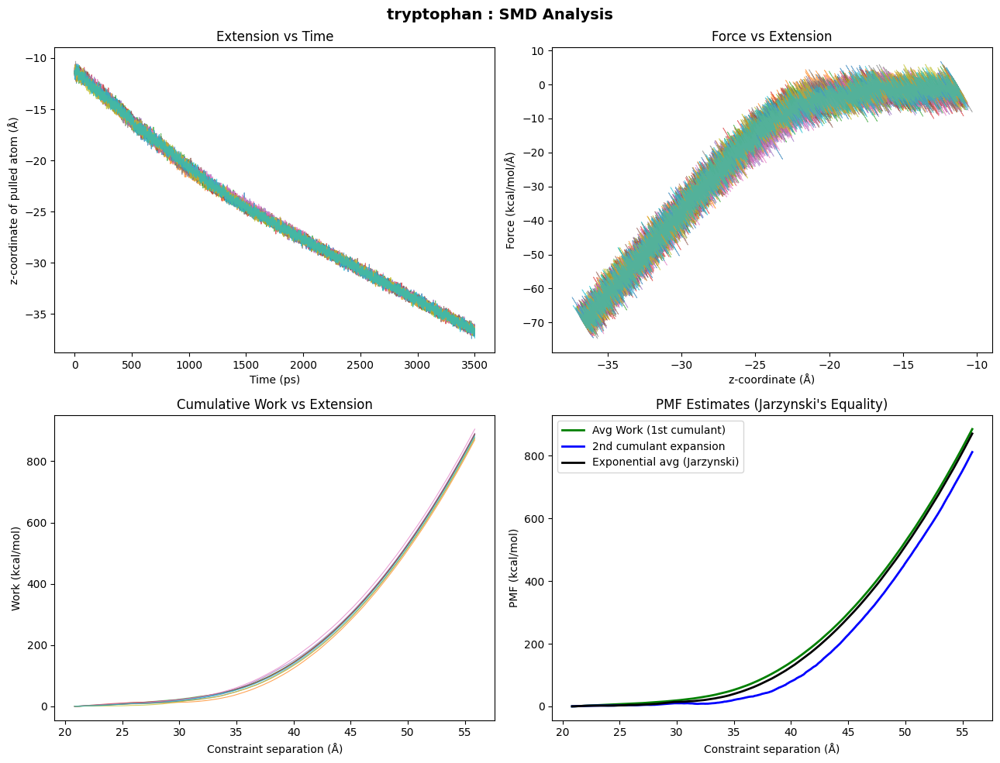


Protein: tyrosine
tyrosine: c1z = 0.0, c2z = 14.4, initial separation = 14.400 Å


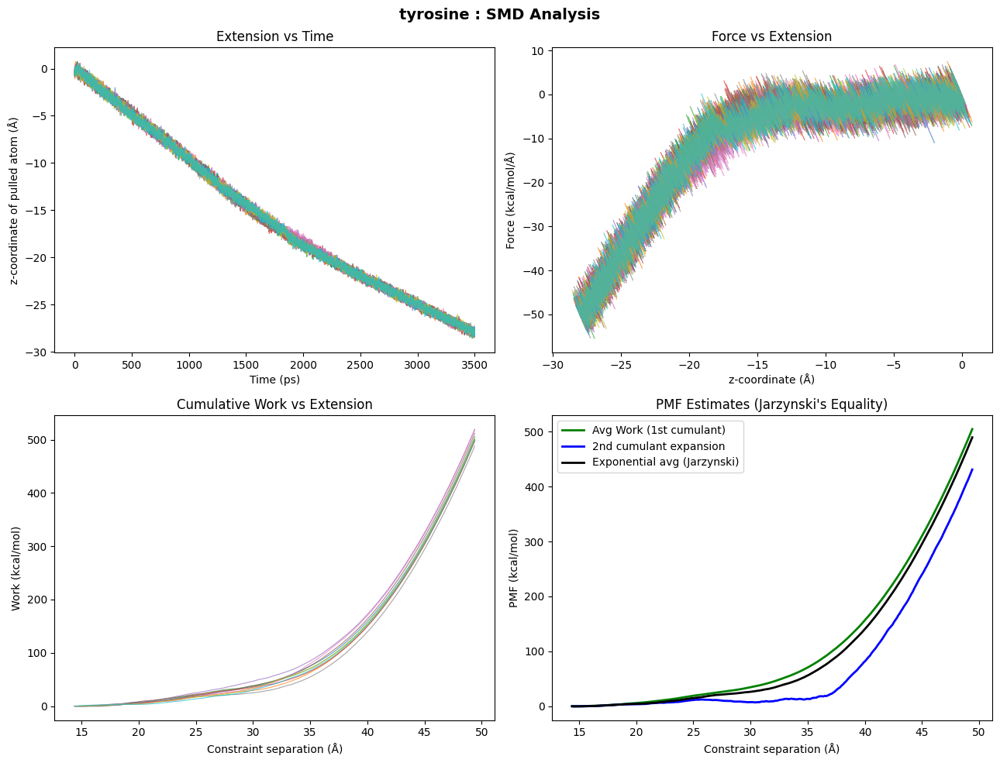


Protein: valine
valine: c1z = -2.033, c2z = 16.212, initial separation = 18.245 Å


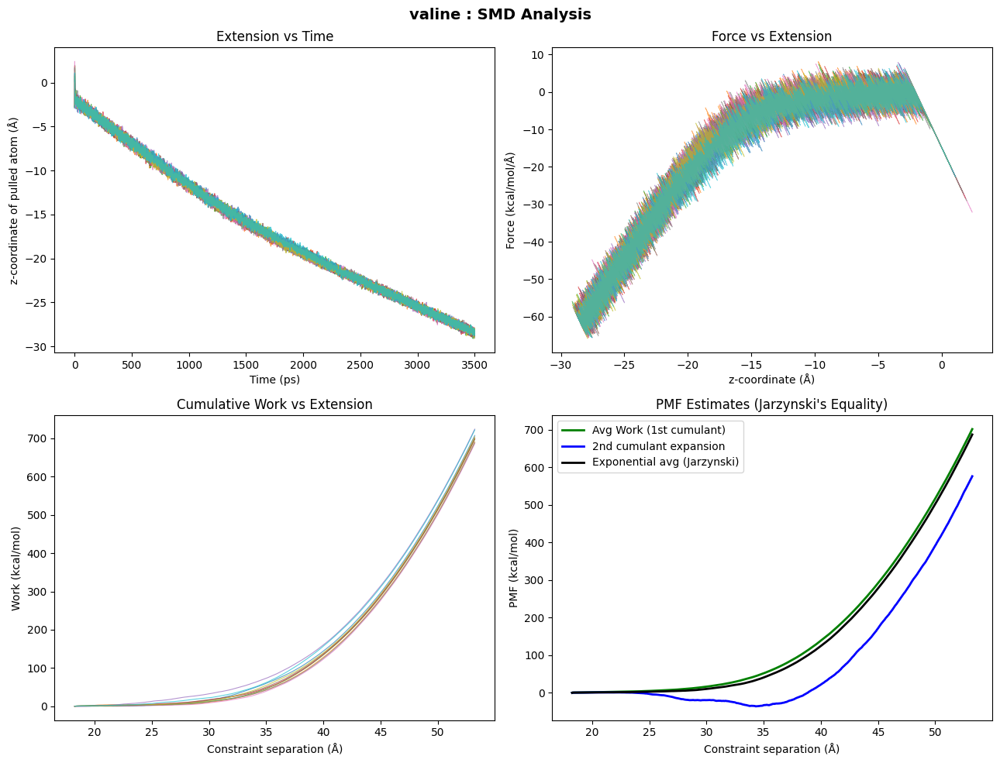

In [95]:
# ============================================================
# CELL 5 — Plot everything for all proteins
# ============================================================
for protein in proteins:
    print(f"\n{'='*50}\nProtein: {protein}\n{'='*50}")

    c1z, c2z            = parse_constraints(protein)
    t_arr, z_arr, f_arr = load_trajectories(protein, n_traj)
    c, W                = compute_extension_and_work(t_arr, f_arr, c1z, c2z)
    c_shifted           = c + c1z - c2z          # starts at 0
    Fexp, F1, F2        = compute_pmf(W, T)

    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    fig.suptitle(f"{protein} : SMD Analysis", fontsize=14, fontweight='bold')

    # --- Plot 1: Extension vs Time ---
    ax = axes[0, 0]
    ax.plot(t_arr[:, 0], z_arr, alpha=0.7, lw=0.8)
    ax.set_xlabel("Time (ps)")
    ax.set_ylabel("z-coordinate of pulled atom (Å)")
    ax.set_title("Extension vs Time")

    # --- Plot 2: Force vs Extension ---
    ax = axes[0, 1]
    for i in range(z_arr.shape[1]):
        ax.plot(z_arr[:, i], f_arr[:, i], alpha=0.6, lw=0.6)
    ax.set_xlabel("z-coordinate (Å)")
    ax.set_ylabel("Force (kcal/mol/Å)")
    ax.set_title("Force vs Extension")

    # --- Plot 3: Work curves ---
    ax = axes[1, 0]
    ax.plot(c, W, alpha=0.7, lw=0.8)
    ax.set_xlabel("Constraint separation (Å)")
    ax.set_ylabel("Work (kcal/mol)")
    ax.set_title("Cumulative Work vs Extension")

    # --- Plot 4: PMF estimates ---
    ax = axes[1, 1]
    ax.plot(c, F1,   color='green', lw=2, label='Avg Work (1st cumulant)')
    ax.plot(c, F2,   color='blue',  lw=2, label='2nd cumulant expansion')
    ax.plot(c, Fexp, color='black', lw=2, label='Exponential avg (Jarzynski)')
    ax.set_xlabel("Constraint separation (Å)")
    ax.set_ylabel("PMF (kcal/mol)")
    ax.set_title("PMF Estimates (Jarzynski's Equality)")
    ax.legend()

    plt.tight_layout()
    # plt.savefig(f"{base_dir}/{protein}/{protein}_pmf_analysis.png", dpi=150)
    plt.show()

alanine: c1z = -0.32, c2z = 14.68, initial separation = 15.000 Å
arginine: c1z = -0.4, c2z = 14.58, initial separation = 14.980 Å
aspartic_acid: c1z = -0.23, c2z = 29.71, initial separation = 29.940 Å
asparagine: c1z = -0.23, c2z = 30.18, initial separation = 30.410 Å
cysteine: c1z = -0.12, c2z = 10.73, initial separation = 10.850 Å
glutamine: c1z = 0.0, c2z = 30.321, initial separation = 30.321 Å
glutamic_acid: c1z = 2.444, c2z = 30.625, initial separation = 28.181 Å
glycine: c1z = 2.393, c2z = 33.951, initial separation = 31.558 Å
histidine: c1z = 0.0, c2z = 25.839, initial separation = 25.839 Å
isoleucine: c1z = -7.345, c2z = 7.013, initial separation = 14.358 Å
leucine: c1z = -7.378, c2z = 7.02, initial separation = 14.398 Å
lysine: c1z = 2.145, c2z = 29.602, initial separation = 27.457 Å
methionine: c1z = 0.0, c2z = 13.689, initial separation = 13.689 Å
phenylalanine: c1z = -8.127, c2z = 5.706, initial separation = 13.833 Å
proline: c1z = 0.0, c2z = 26.854, initial separation = 26

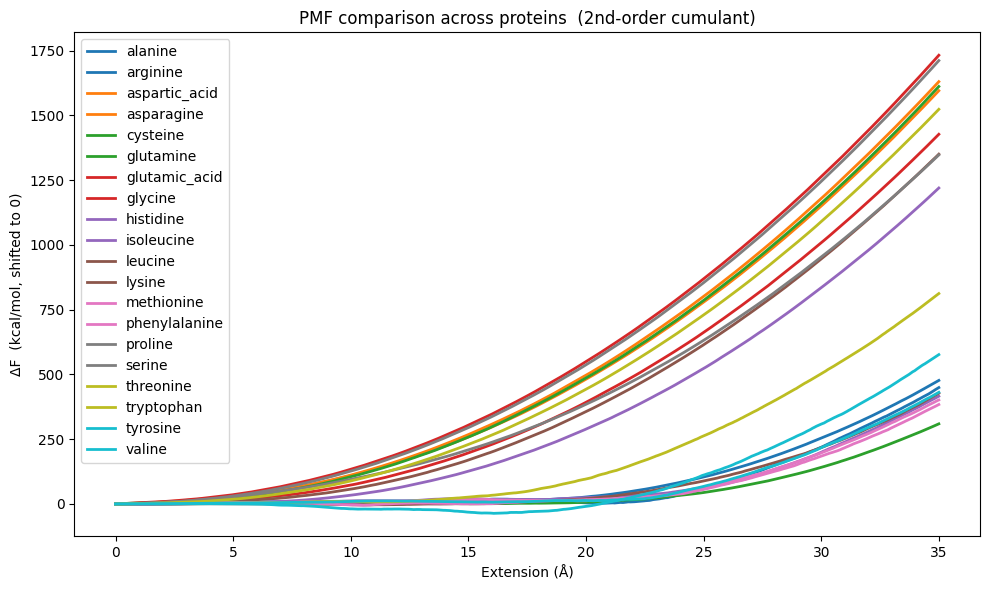

In [96]:
# ============================================================
# CELL 6 — Side-by-side PMF comparison across all proteins
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(proteins)))

for protein, color in zip(proteins, colors):
    c1z, c2z            = parse_constraints(protein)
    t_arr, z_arr, f_arr = load_trajectories(protein, n_traj)
    c, W                = compute_extension_and_work(t_arr, f_arr, c1z, c2z)
    c=c+c1z-c2z
    Fexp, F1, F2        = compute_pmf(W, T)

    # Shift so all PMFs start at 0 for fair comparison
    ax.plot(c, F2 - F2[0], color=color, lw=2, label=protein)

ax.set_xlabel("Extension (Å)")
ax.set_ylabel("ΔF  (kcal/mol, shifted to 0)")
ax.set_title("PMF comparison across proteins  (2nd-order cumulant)")
ax.legend()
plt.tight_layout()
# plt.savefig(f"{base_dir}/pmf_comparison_all.png", dpi=150)
plt.show()

In [97]:
import plotly.graph_objects as go

fig = go.Figure()

for protein, color in zip(proteins, [
    '#1f77b4', '#2ca02c', '#8c564b', '#7f7f7f', '#17becf'
]):
    c1z, c2z            = parse_constraints(protein)
    t_arr, z_arr, f_arr = load_trajectories(protein, n_traj)
    c, W                = compute_extension_and_work(t_arr, f_arr, c1z, c2z)
    c=c+c1z-c2z
    _, _, F2            = compute_pmf(W, T)

    F2_shifted = F2 - F2[0]

    fig.add_trace(go.Scatter(
        x=c, y=F2_shifted,
        mode='lines',
        name=protein,
        line=dict(color=color, width=2)
    ))

fig.update_layout(
    title="PMF comparison across proteins (2nd-order cumulant)",
    xaxis=dict(title="Constraint separation (Å)", range=[0, 35]),
    yaxis=dict(title="ΔF (kcal/mol, shifted to 0)", range=[0, 100]),
    legend=dict(x=0.02, y=0.98),
    width=900, height=600,
    template='plotly_white'
)

fig.show()

alanine: c1z = -0.32, c2z = 14.68, initial separation = 15.000 Å
arginine: c1z = -0.4, c2z = 14.58, initial separation = 14.980 Å
aspartic_acid: c1z = -0.23, c2z = 29.71, initial separation = 29.940 Å
asparagine: c1z = -0.23, c2z = 30.18, initial separation = 30.410 Å
cysteine: c1z = -0.12, c2z = 10.73, initial separation = 10.850 Å


/tmp/ipykernel_37376/331445626.py:10: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



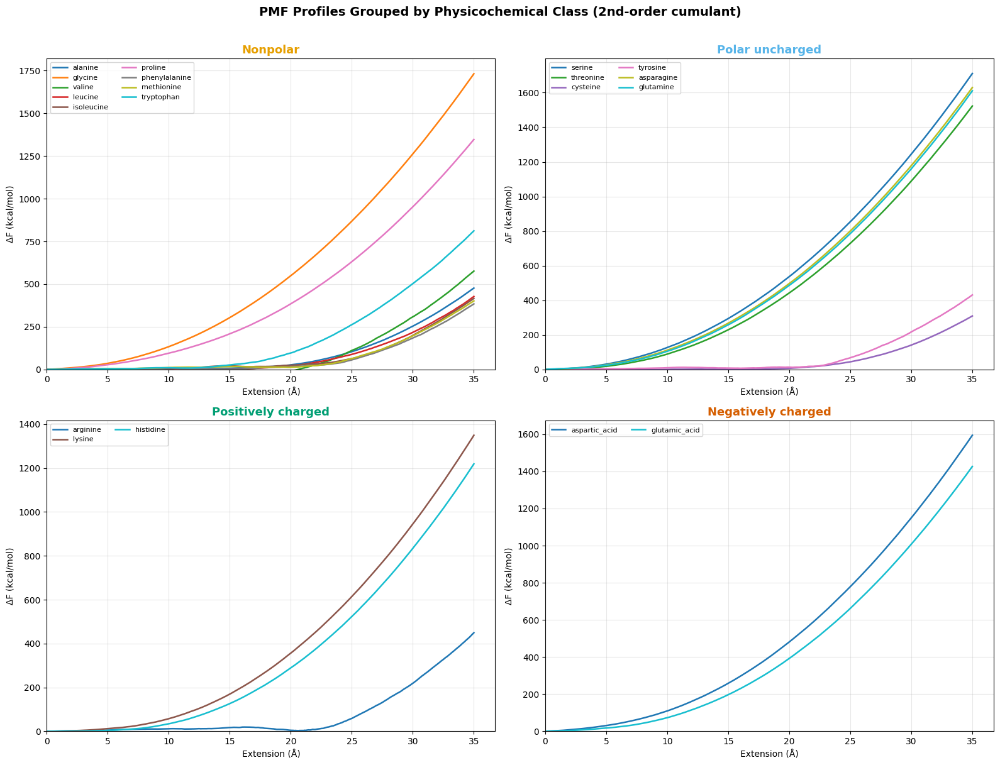

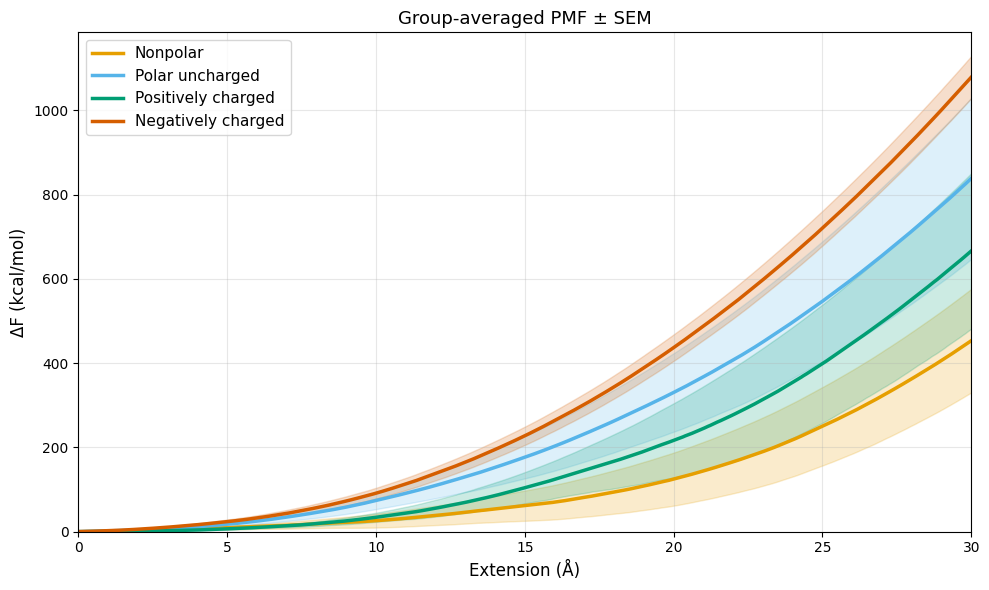

In [98]:
# ============================================================
# IDEA 1: PMF curves grouped by physicochemical class
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax_idx, (group_name, members) in enumerate(groups.items()):
    ax = axes[ax_idx]
    color = group_colors[group_name]
    cmap  = plt.cm.get_cmap('tab10', len(members))

    for j, protein in enumerate(members):
        if protein not in results:
            continue
        r  = results[protein]
        F2 = r['F2'] - r['F2'][0]
        ax.plot(r['c'], F2, lw=1.8, label=protein, color=cmap(j))

    ax.set_title(f"{group_name}", fontsize=13, fontweight='bold',
                 color=group_colors[group_name])
    ax.set_xlabel("Extension (Å)")
    ax.set_ylabel("ΔF (kcal/mol)")
    ax.legend(fontsize=8, ncol=2)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)

plt.suptitle("PMF Profiles Grouped by Physicochemical Class (2nd-order cumulant)",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig(f"{base_dir}/pmf_by_group.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Group-averaged PMF on one axes ──
fig, ax = plt.subplots(figsize=(10, 6))

for group_name, members in groups.items():
    valid = [p for p in members if p in results]
    if not valid:
        continue
    # Interpolate all to common extension axis
    c_common = np.linspace(0, 30, 500)
    F2_interp = []
    for protein in valid:
        r  = results[protein]
        F2 = r['F2'] - r['F2'][0]
        F2_interp.append(np.interp(c_common, r['c'], F2,
                                   left=np.nan, right=np.nan))
    F2_mat  = np.array(F2_interp)
    F2_mean = np.nanmean(F2_mat, axis=0)
    F2_sem  = np.nanstd(F2_mat, axis=0) / np.sqrt(len(valid))

    ax.plot(c_common, F2_mean, lw=2.5, label=group_name,
            color=group_colors[group_name])
    ax.fill_between(c_common, F2_mean - F2_sem, F2_mean + F2_sem,
                    alpha=0.2, color=group_colors[group_name])

ax.set_xlabel("Extension (Å)", fontsize=12)
ax.set_ylabel("ΔF (kcal/mol)", fontsize=12)
ax.set_title("Group-averaged PMF ± SEM", fontsize=13)
ax.set_xlim(0, 30); ax.set_ylim(bottom=0)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig(f"{base_dir}/pmf_group_avg.png", dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_37376/3552441879.py:12: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



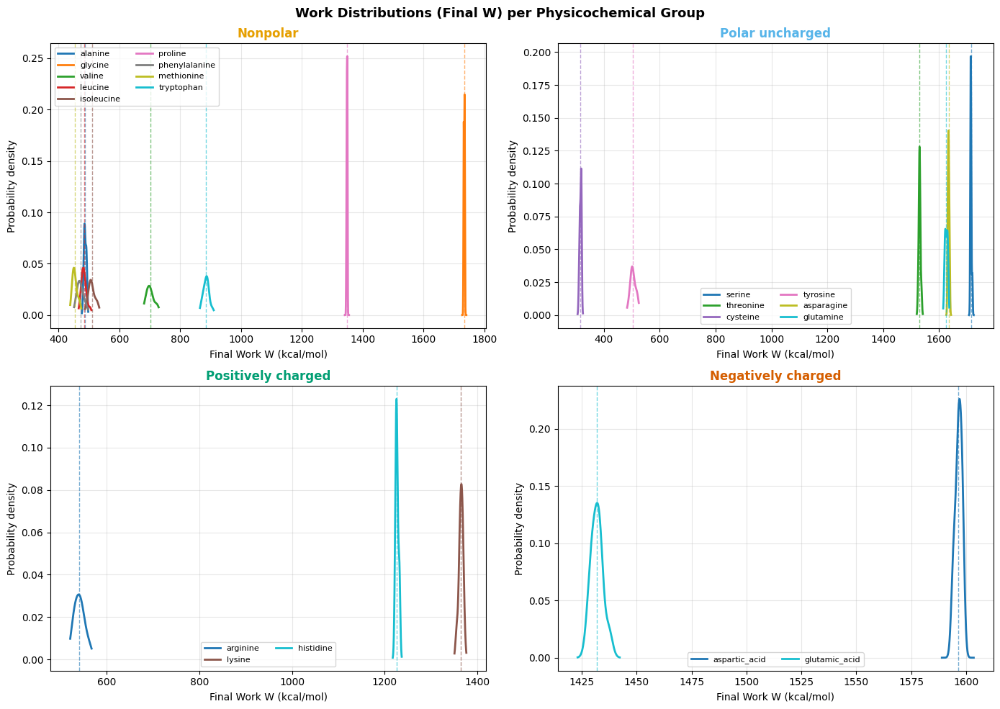

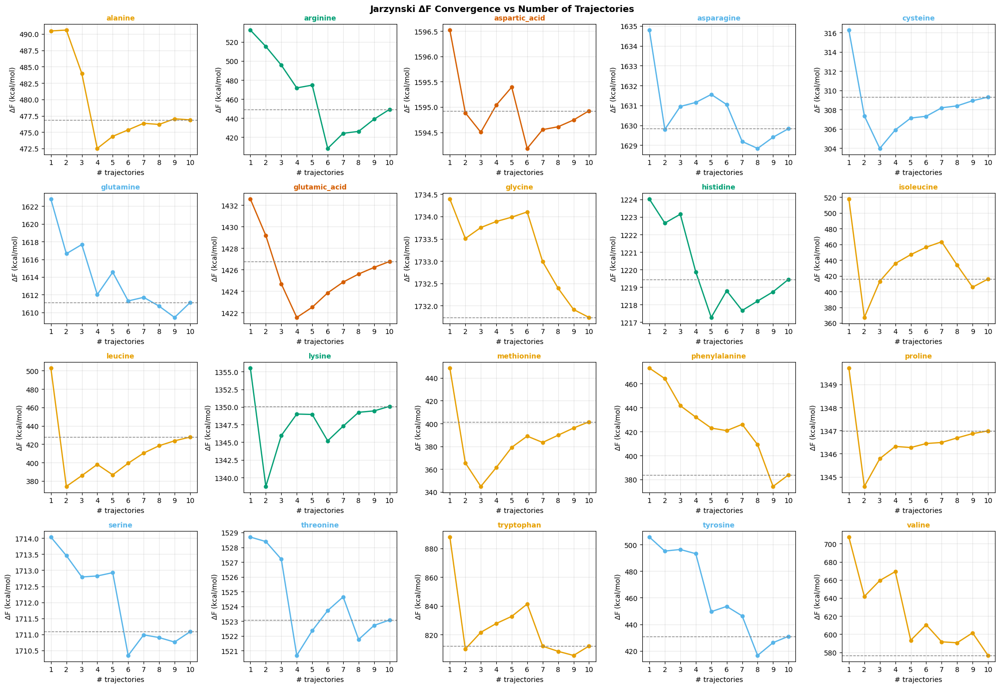

In [99]:
# ============================================================
# IDEA 2: Work distributions (KDE) + ΔF convergence with n_traj
# ============================================================
from scipy.stats import gaussian_kde

# ── Part A: Work distributions per group ──
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax_idx, (group_name, members) in enumerate(groups.items()):
    ax = axes[ax_idx]
    cmap = plt.cm.get_cmap('tab10', len(members))
    for j, protein in enumerate(members):
        if protein not in results:
            continue
        W_fin = results[protein]['W_final']
        kde   = gaussian_kde(W_fin, bw_method='scott')
        x_rng = np.linspace(W_fin.min() - 5, W_fin.max() + 5, 300)
        ax.plot(x_rng, kde(x_rng), lw=2, label=protein, color=cmap(j))
        ax.axvline(np.mean(W_fin), ls='--', lw=1, color=cmap(j), alpha=0.6)

    ax.set_title(group_name, fontsize=12, fontweight='bold',
                 color=group_colors[group_name])
    ax.set_xlabel("Final Work W (kcal/mol)")
    ax.set_ylabel("Probability density")
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

plt.suptitle("Work Distributions (Final W) per Physicochemical Group",
             fontsize=13, fontweight='bold')
plt.tight_layout()
# plt.savefig(f"{base_dir}/work_distributions.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Part B: ΔF convergence as n increases ──
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
axes = axes.flatten()

for idx, protein in enumerate(proteins):
    if protein not in results:
        continue
    ax = axes[idx]
    W  = results[protein]['W']     # (n_steps, n_traj)

    n_range = np.arange(1, n_traj + 1)
    dF_conv = []
    for n in n_range:
        W_sub = W[:, :n]
        _, _, F2_sub = compute_pmf(W_sub, T)
        dF_conv.append(F2_sub[-1] - F2_sub[0])

    color = group_colors[get_group(protein)]
    ax.plot(n_range, dF_conv, 'o-', color=color, lw=1.8, ms=5)
    ax.axhline(dF_conv[-1], ls='--', color='gray', lw=1)
    ax.set_title(protein, fontsize=10, color=color, fontweight='bold')
    ax.set_xlabel("# trajectories")
    ax.set_ylabel("ΔF (kcal/mol)")
    ax.set_xticks(n_range)
    ax.grid(alpha=0.3)

# Hide unused subplots
for idx in range(len(proteins), len(axes)):
    axes[idx].axis('off')

plt.suptitle("Jarzynski ΔF Convergence vs Number of Trajectories",
             fontsize=13, fontweight='bold')
plt.tight_layout()
# plt.savefig(f"{base_dir}/dF_convergence.png", dpi=150, bbox_inches='tight')
plt.show()

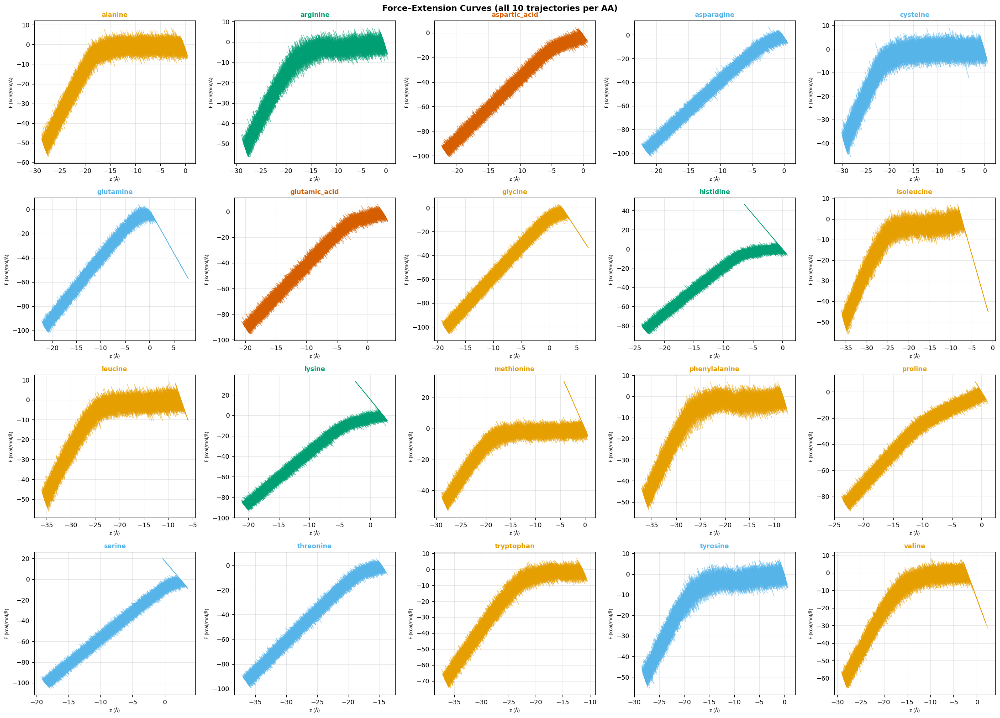

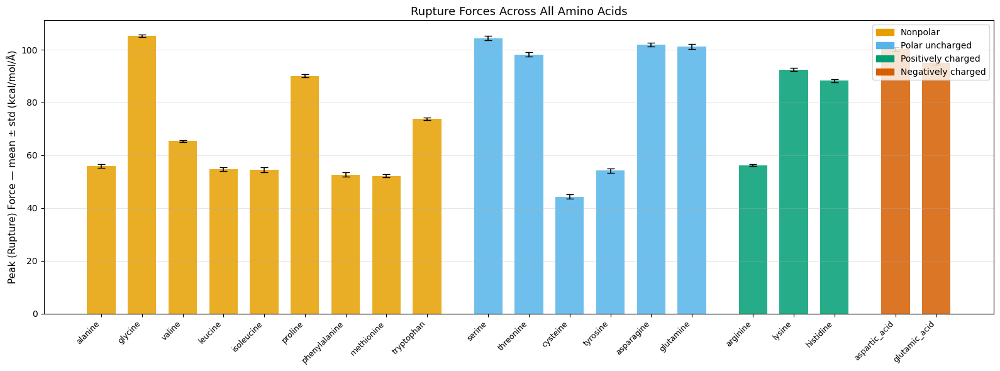

In [100]:
# ============================================================
# IDEA 3: Force-extension curves + rupture force comparison
# ============================================================

# ── Part A: Force-extension per amino acid, coloured by group ──
fig, axes = plt.subplots(4, 5, figsize=(22, 16))
axes = axes.flatten()

for idx, protein in enumerate(proteins):
    if protein not in results:
        continue
    ax    = axes[idx]
    r     = results[protein]
    color = group_colors[get_group(protein)]

    for i in range(r['f_arr'].shape[1]):
        ax.plot(r['z_arr'][:, i], r['f_arr'][:, i],
                alpha=0.5, lw=0.7, color=color)

    ax.set_title(protein, fontsize=10, color=color, fontweight='bold')
    ax.set_xlabel("z (Å)", fontsize=7)
    ax.set_ylabel("F (kcal/mol/Å)", fontsize=7)
    ax.grid(alpha=0.3)

for idx in range(len(proteins), len(axes)):
    axes[idx].axis('off')

plt.suptitle("Force–Extension Curves (all 10 trajectories per AA)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
# plt.savefig(f"{base_dir}/force_extension_all.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Part B: Rupture force bar chart grouped by class ──
fig, ax = plt.subplots(figsize=(16, 6))

x_pos   = 0
x_ticks = []
x_labels= []

for group_name, members in groups.items():
    valid = [p for p in members if p in results]
    for protein in valid:
        r     = results[protein]
        color = group_colors[group_name]
        ax.bar(x_pos, r['mean_rupF'], yerr=r['std_rupF'],
               color=color, width=0.7, capsize=4, alpha=0.85,
               error_kw=dict(elinewidth=1.2))
        x_ticks.append(x_pos)
        x_labels.append(protein)
        x_pos += 1
    x_pos += 0.5   # gap between groups

ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel("Peak (Rupture) Force — mean ± std (kcal/mol/Å)", fontsize=11)
ax.set_title("Rupture Forces Across All Amino Acids", fontsize=13)

# Group legend
from matplotlib.patches import Patch
legend_handles = [Patch(color=group_colors[g], label=g) for g in groups]
ax.legend(handles=legend_handles, fontsize=10, loc='upper right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
# plt.savefig(f"{base_dir}/rupture_forces.png", dpi=150, bbox_inches='tight')
plt.show()

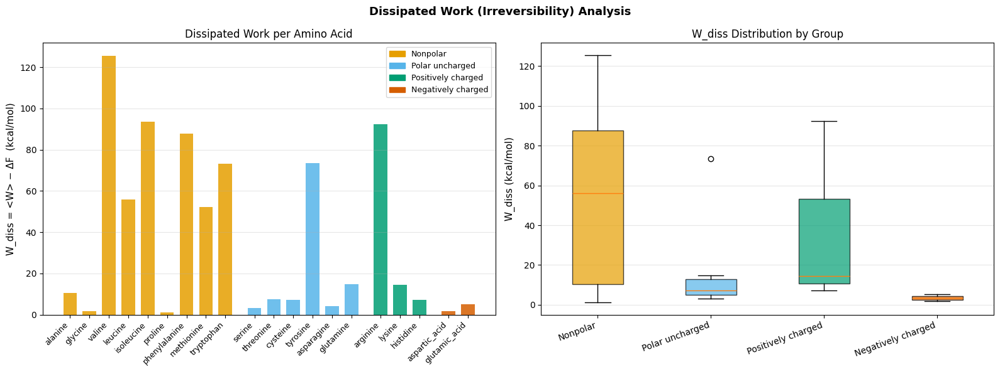


Amino Acid   Group                  <W>          ΔF           W_diss      
----------------------------------------------------------------------
alanine      Nonpolar               487.33       476.87       10.46       
glycine      Nonpolar               1733.42      1731.74      1.69        
valine       Nonpolar               701.97       576.47       125.50      
leucine      Nonpolar               483.64       427.66       55.98       
isoleucine   Nonpolar               509.56       415.93       93.63       
proline      Nonpolar               1348.19      1346.99      1.21        
phenylalanine Nonpolar               471.70       383.90       87.80       
methionine   Nonpolar               453.86       401.51       52.35       
tryptophan   Nonpolar               885.37       812.07       73.30       
serine       Polar uncharged        1714.28      1711.08      3.19        
threonine    Polar uncharged        1530.48      1523.08      7.40        
cysteine     Polar uncharge

In [101]:
# ============================================================
# IDEA 4: Dissipated work W_diss = <W> − ΔF
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Bar chart: W_diss per amino acid ──
ax = axes[0]
x_pos, x_ticks, x_labels = 0, [], []

for group_name, members in groups.items():
    valid = [p for p in members if p in results]
    for protein in valid:
        color  = group_colors[group_name]
        W_diss = results[protein]['W_diss']
        ax.bar(x_pos, W_diss, color=color, width=0.7, alpha=0.85)
        x_ticks.append(x_pos)
        x_labels.append(protein)
        x_pos += 1
    x_pos += 0.5

ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel("W_diss = <W> − ΔF  (kcal/mol)", fontsize=11)
ax.set_title("Dissipated Work per Amino Acid", fontsize=12)
legend_handles = [Patch(color=group_colors[g], label=g) for g in groups]
ax.legend(handles=legend_handles, fontsize=9)
ax.grid(axis='y', alpha=0.3)

# ── Box plot: W_diss distribution within each group ──
ax = axes[1]
group_wdiss = []
group_names = []

for group_name, members in groups.items():
    vals = [results[p]['W_diss'] for p in members if p in results]
    if vals:
        group_wdiss.append(vals)
        group_names.append(group_name)

bp = ax.boxplot(group_wdiss, patch_artist=True, notch=False)
for patch, gname in zip(bp['boxes'], group_names):
    patch.set_facecolor(group_colors[gname])
    patch.set_alpha(0.7)

ax.set_xticklabels(group_names, rotation=20, ha='right', fontsize=10)
ax.set_ylabel("W_diss (kcal/mol)", fontsize=11)
ax.set_title("W_diss Distribution by Group", fontsize=12)
ax.grid(axis='y', alpha=0.3)

plt.suptitle("Dissipated Work (Irreversibility) Analysis", fontsize=13, fontweight='bold')
plt.tight_layout()
# plt.savefig(f"{base_dir}/dissipated_work.png", dpi=150, bbox_inches='tight')
plt.show()

# Print summary table
print(f"\n{'Amino Acid':<12} {'Group':<22} {'<W>':<12} {'ΔF':<12} {'W_diss':<12}")
print("-" * 70)
for group_name, members in groups.items():
    for protein in members:
        if protein not in results:
            continue
        r = results[protein]
        print(f"{protein:<12} {group_name:<22} {r['mean_W']:<12.2f} "
              f"{r['delta_F']:<12.2f} {r['W_diss']:<12.2f}")

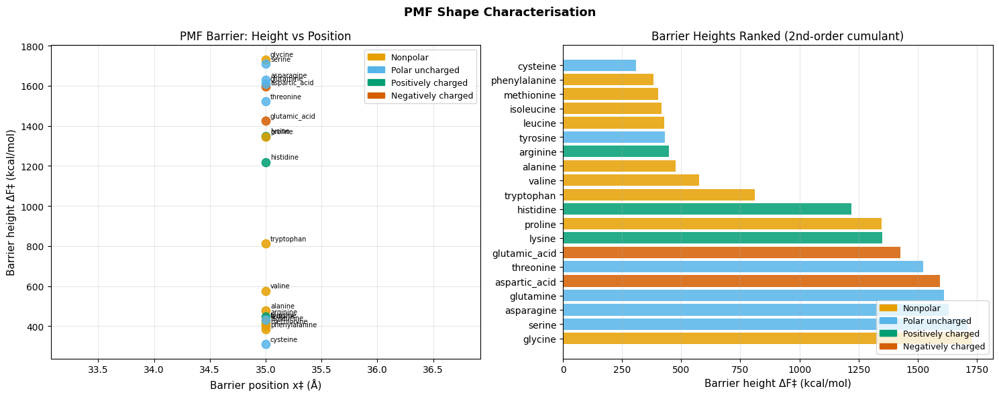

In [102]:
# ============================================================
# IDEA 5: PMF barrier height ΔF‡ and position x‡
# ============================================================
from matplotlib.patches import Patch

# ── Scatter: barrier position vs barrier height ──
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
for protein in proteins:
    if protein not in results:
        continue
    r      = results[protein]
    group  = get_group(protein)
    color  = group_colors[group]
    ax.scatter(r['x_barrier'], r['delta_F'],
               color=color, s=80, zorder=3, alpha=0.85)
    ax.annotate(protein, (r['x_barrier'], r['delta_F']),
                textcoords='offset points', xytext=(5, 3), fontsize=7)

ax.set_xlabel("Barrier position x‡ (Å)", fontsize=11)
ax.set_ylabel("Barrier height ΔF‡ (kcal/mol)", fontsize=11)
ax.set_title("PMF Barrier: Height vs Position", fontsize=12)
legend_handles = [Patch(color=group_colors[g], label=g) for g in groups]
ax.legend(handles=legend_handles, fontsize=9)
ax.grid(alpha=0.3)

# ── Bar: barrier heights ranked ──
ax = axes[1]
sorted_proteins = sorted(
    [p for p in proteins if p in results],
    key=lambda p: results[p]['delta_F'], reverse=True
)
colors_sorted = [group_colors[get_group(p)] for p in sorted_proteins]
dF_vals       = [results[p]['delta_F'] for p in sorted_proteins]

ax.barh(sorted_proteins, dF_vals, color=colors_sorted, alpha=0.85)
ax.set_xlabel("Barrier height ΔF‡ (kcal/mol)", fontsize=11)
ax.set_title("Barrier Heights Ranked (2nd-order cumulant)", fontsize=12)
ax.grid(axis='x', alpha=0.3)
legend_handles = [Patch(color=group_colors[g], label=g) for g in groups]
ax.legend(handles=legend_handles, fontsize=9, loc='lower right')

plt.suptitle("PMF Shape Characterisation", fontsize=13, fontweight='bold')
plt.tight_layout()
# plt.savefig(f"{base_dir}/pmf_barrier_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_37376/402666627.py:28: NearConstantInputWarning:

An input array is nearly constant; the computed correlation coefficient may be inaccurate.



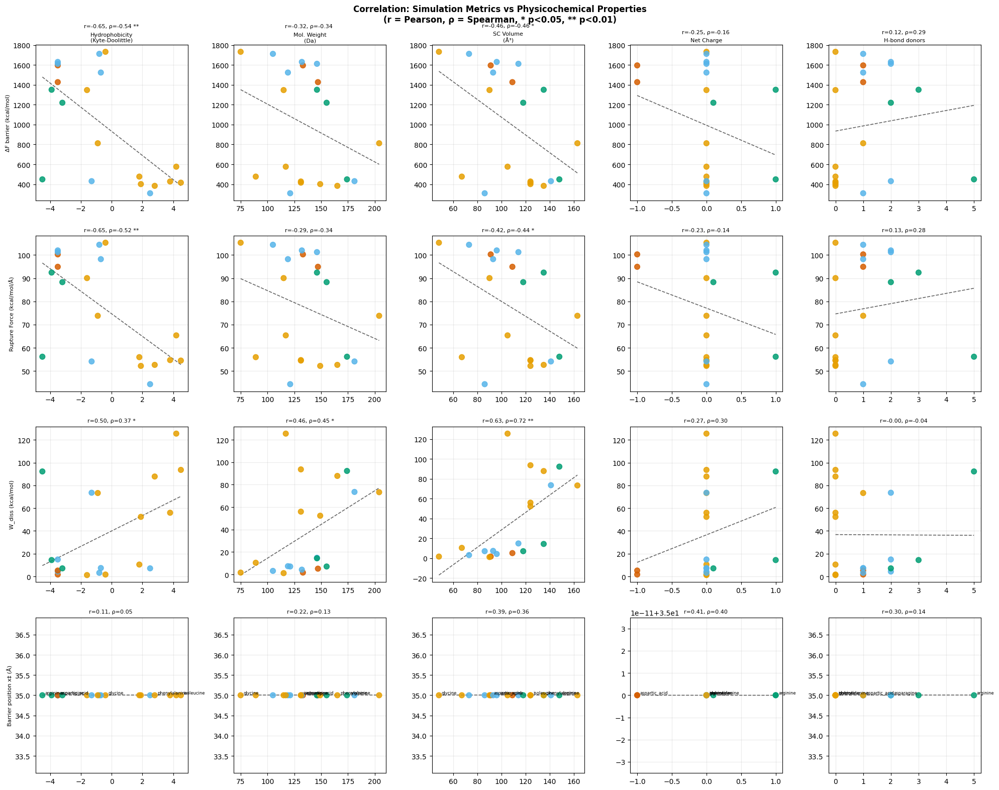


Metric                         Property                      Pearson r      p-val   Spearman ρ      p-val
----------------------------------------------------------------------------------------------------
ΔF barrier (kcal/mol)          Hydrophobicity (Kyte-Doolittle)     -0.650     0.0019       -0.537     0.0147  **
ΔF barrier (kcal/mol)          Mol. Weight (Da)                 -0.321     0.1671       -0.336     0.1471  
ΔF barrier (kcal/mol)          SC Volume (Å³)                   -0.463     0.0397       -0.462     0.0404  *
ΔF barrier (kcal/mol)          Net Charge                       -0.246     0.2949       -0.162     0.4943  
ΔF barrier (kcal/mol)          H-bond donors                     0.120     0.6144        0.294     0.2078  
Rupture Force (kcal/mol/Å)     Hydrophobicity (Kyte-Doolittle)     -0.652     0.0018       -0.523     0.0180  **
Rupture Force (kcal/mol/Å)     Mol. Weight (Da)                 -0.285     0.2224       -0.341     0.1414  
Rupture Force (kcal/mol/Å

/tmp/ipykernel_37376/402666627.py:71: NearConstantInputWarning:

An input array is nearly constant; the computed correlation coefficient may be inaccurate.



In [103]:
# ============================================================
# IDEA 6: Correlation of simulation metrics with AA properties
# ============================================================
from scipy.stats import pearsonr, spearmanr

prop_labels = ['Hydrophobicity\n(Kyte-Doolittle)', 'Mol. Weight\n(Da)',
               'SC Volume\n(Å³)', 'Net Charge', 'H-bond donors']

sim_metrics = {
    'ΔF barrier (kcal/mol)':       lambda p: results[p]['delta_F'],
    'Rupture Force (kcal/mol/Å)':  lambda p: results[p]['mean_rupF'],
    'W_diss (kcal/mol)':           lambda p: results[p]['W_diss'],
    'Barrier position x‡ (Å)':    lambda p: results[p]['x_barrier'],
}

valid_proteins = [p for p in proteins if p in results and p in aa_properties]

fig, axes = plt.subplots(len(sim_metrics), len(prop_labels),
                          figsize=(20, 16))

for row_idx, (metric_name, metric_fn) in enumerate(sim_metrics.items()):
    y_vals = np.array([metric_fn(p) for p in valid_proteins])

    for col_idx, prop_idx in enumerate(range(5)):
        ax    = axes[row_idx, col_idx]
        x_vals = np.array([aa_properties[p][prop_idx] for p in valid_proteins])

        r_p, p_p = pearsonr(x_vals, y_vals)
        r_s, p_s = spearmanr(x_vals, y_vals)

        colors_pt = [group_colors[get_group(p)] for p in valid_proteins]
        ax.scatter(x_vals, y_vals, c=colors_pt, s=60, zorder=3, alpha=0.85)

        # Regression line
        m, b   = np.polyfit(x_vals, y_vals, 1)
        x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
        ax.plot(x_line, m * x_line + b, 'k--', lw=1.2, alpha=0.6)

        sig_marker = '**' if min(p_p, p_s) < 0.01 else ('*' if min(p_p, p_s) < 0.05 else '')
        ax.set_title(f"r={r_p:.2f}, ρ={r_s:.2f} {sig_marker}", fontsize=8)

        if row_idx == 0:
            ax.set_xlabel(prop_labels[col_idx], fontsize=8)
            ax.xaxis.set_label_position('top')
        if col_idx == 0:
            ax.set_ylabel(metric_name, fontsize=8)
        ax.grid(alpha=0.25)

        # Annotate outliers (>1.5 IQR)
        q1, q3 = np.percentile(y_vals, [25, 75])
        iqr = q3 - q1
        for i, (xi, yi, p) in enumerate(zip(x_vals, y_vals, valid_proteins)):
            if yi > q3 + 1.5 * iqr or yi < q1 - 1.5 * iqr:
                ax.annotate(p, (xi, yi), textcoords='offset points',
                            xytext=(4, 2), fontsize=6)

plt.suptitle("Correlation: Simulation Metrics vs Physicochemical Properties\n"
             "(r = Pearson, ρ = Spearman, * p<0.05, ** p<0.01)",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{base_dir}/correlations.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Print correlation table ──
print(f"\n{'Metric':<30} {'Property':<28} {'Pearson r':>10} {'p-val':>10} {'Spearman ρ':>12} {'p-val':>10}")
print("-" * 100)
for metric_name, metric_fn in sim_metrics.items():
    y_vals = np.array([metric_fn(p) for p in valid_proteins])
    for pidx, plabel in enumerate(prop_labels):
        x_vals = np.array([aa_properties[p][pidx] for p in valid_proteins])
        r_p, p_p = pearsonr(x_vals, y_vals)
        r_s, p_s = spearmanr(x_vals, y_vals)
        sig = '**' if min(p_p, p_s) < 0.01 else ('*' if min(p_p, p_s) < 0.05 else '')
        print(f"{metric_name:<30} {plabel.replace(chr(10),' '):<28} "
              f"{r_p:>10.3f} {p_p:>10.4f} {r_s:>12.3f} {p_s:>10.4f}  {sig}")

/tmp/ipykernel_37376/1500006922.py:48: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



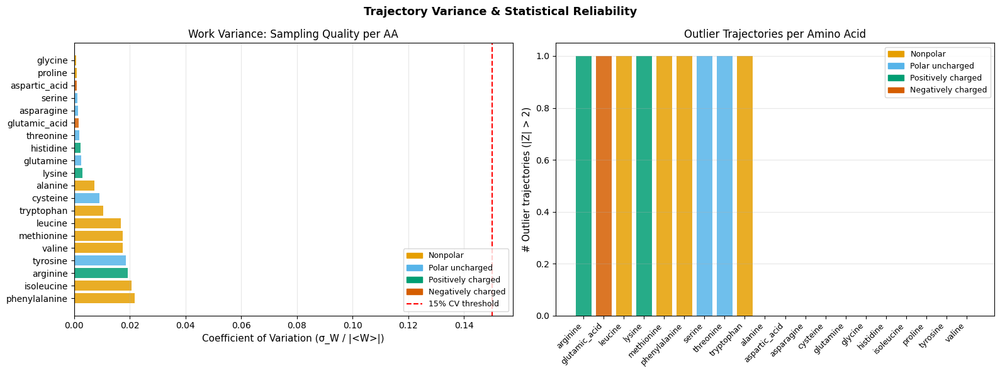


── Outlier Trajectory Report (|Z-score of final W| > 2) ──
Amino Acid   Group                  Outlier traj indices
------------------------------------------------------------
alanine      Nonpolar               []
arginine     Positively charged     [5] ⚠
aspartic_acid Negatively charged     []
asparagine   Polar uncharged        []
cysteine     Polar uncharged        []
glutamine    Polar uncharged        []
glutamic_acid Negatively charged     [2] ⚠
glycine      Nonpolar               []
histidine    Positively charged     []
isoleucine   Nonpolar               []
leucine      Nonpolar               [0] ⚠
lysine       Positively charged     [0] ⚠
methionine   Nonpolar               [1] ⚠
phenylalanine Nonpolar               [8] ⚠
proline      Nonpolar               []
serine       Polar uncharged        [5] ⚠
threonine    Polar uncharged        [3] ⚠
tryptophan   Nonpolar               [6] ⚠
tyrosine     Polar uncharged        []
valine       Nonpolar               []


In [104]:
# ============================================================
# IDEA 7: Trajectory variance & outlier detection
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Part A: Coefficient of variation (std/mean) of final W ──
ax = axes[0]
sorted_by_cv = sorted(
    [p for p in proteins if p in results],
    key=lambda p: results[p]['std_W'] / (abs(results[p]['mean_W']) + 1e-9),
    reverse=True
)
cv_vals  = [results[p]['std_W'] / (abs(results[p]['mean_W']) + 1e-9) for p in sorted_by_cv]
col_list = [group_colors[get_group(p)] for p in sorted_by_cv]

ax.barh(sorted_by_cv, cv_vals, color=col_list, alpha=0.85)
ax.axvline(0.15, ls='--', color='red', lw=1.5, label='15% CV threshold')
ax.set_xlabel("Coefficient of Variation (σ_W / |<W>|)", fontsize=11)
ax.set_title("Work Variance: Sampling Quality per AA", fontsize=12)
ax.legend(fontsize=9)
ax.grid(axis='x', alpha=0.3)
legend_handles = [Patch(color=group_colors[g], label=g) for g in groups]
ax.legend(handles=legend_handles + [
    plt.Line2D([0], [0], ls='--', color='red', label='15% CV threshold')
], fontsize=9, loc='lower right')

# ── Part B: Outlier trajectories per AA (Z-score of final W) ──
ax = axes[1]
outlier_counts = {}
outlier_detail = {}

for protein in proteins:
    if protein not in results:
        continue
    W_fin  = results[protein]['W_final']
    z_scores = np.abs(stats.zscore(W_fin))
    n_out  = int(np.sum(z_scores > 2.0))
    outlier_counts[protein] = n_out
    outlier_detail[protein] = np.where(z_scores > 2.0)[0].tolist()

sorted_oc = sorted(outlier_counts.keys(),
                   key=lambda p: outlier_counts[p], reverse=True)
oc_vals   = [outlier_counts[p] for p in sorted_oc]
col_list2 = [group_colors[get_group(p)] for p in sorted_oc]

bars = ax.bar(sorted_oc, oc_vals, color=col_list2, alpha=0.85)
ax.set_xticklabels(sorted_oc, rotation=45, ha='right', fontsize=9)
ax.set_ylabel("# Outlier trajectories (|Z| > 2)", fontsize=11)
ax.set_title("Outlier Trajectories per Amino Acid", fontsize=12)
ax.grid(axis='y', alpha=0.3)
legend_handles = [Patch(color=group_colors[g], label=g) for g in groups]
ax.legend(handles=legend_handles, fontsize=9)

plt.suptitle("Trajectory Variance & Statistical Reliability", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{base_dir}/variance_outliers.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Print outlier report ──
print("\n── Outlier Trajectory Report (|Z-score of final W| > 2) ──")
print(f"{'Amino Acid':<12} {'Group':<22} {'Outlier traj indices'}")
print("-" * 60)
for protein in proteins:
    if protein not in results:
        continue
    idxs = outlier_detail[protein]
    flag = " ⚠" if idxs else ""
    print(f"{protein:<12} {get_group(protein):<22} {idxs}{flag}")

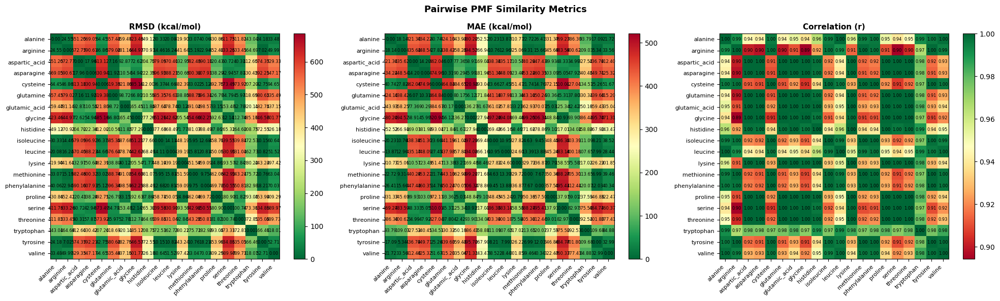


GROUP-LEVEL PMF COMPARISON

Nonpolar:
  Members: alanine, glycine, valine, leucine, isoleucine, proline, phenylalanine, methionine, tryptophan
  Mean barrier height: 730.35 ± 174.79 kcal/mol
  Barrier position: 35.00 Å
  Mean integrated PMF: 6356.79 kcal·Å/mol

Polar uncharged:
  Members: serine, threonine, cysteine, tyrosine, asparagine, glutamine
  Mean barrier height: 1202.56 ± 216.88 kcal/mol
  Barrier position: 35.00 Å
  Mean integrated PMF: 12763.27 kcal·Å/mol

Positively charged:
  Members: arginine, lysine, histidine
  Mean barrier height: 1006.25 ± 142.01 kcal/mol
  Barrier position: 35.00 Å
  Mean integrated PMF: 9495.06 kcal·Å/mol

Negatively charged:
  Members: aspartic_acid, glutamic_acid
  Mean barrier height: 1510.84 ± 38.68 kcal/mol
  Barrier position: 35.00 Å
  Mean integrated PMF: 16481.73 kcal·Å/mol


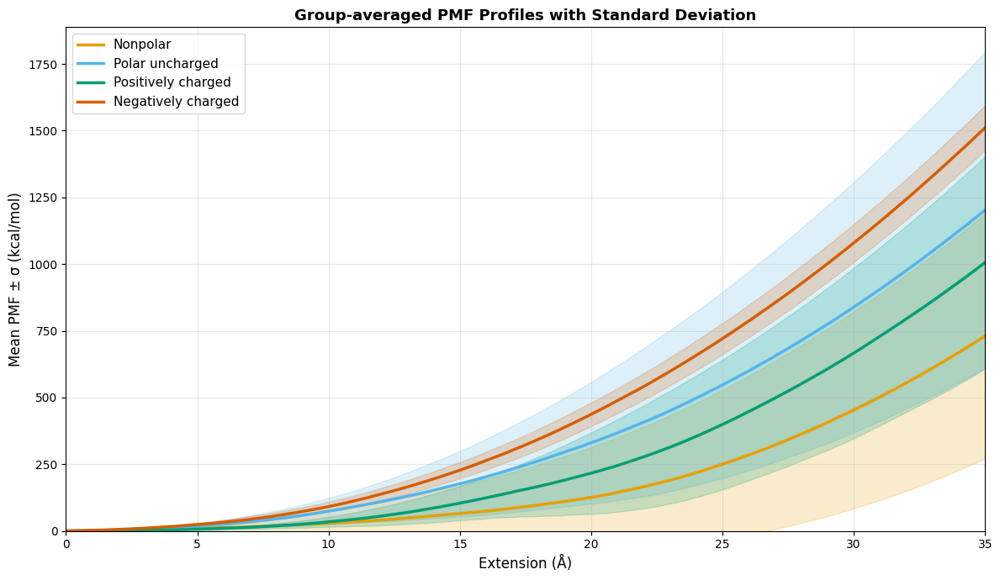


STATISTICAL TESTS

One-way ANOVA on barrier heights (ΔF) across groups:
  F-statistic: 1.6887
  p-value: 2.0944e-01
  ✗ No significant difference (p ≥ 0.05)

Kruskal-Wallis test (non-parametric):
  H-statistic: 3.4317
  p-value: 3.2972e-01


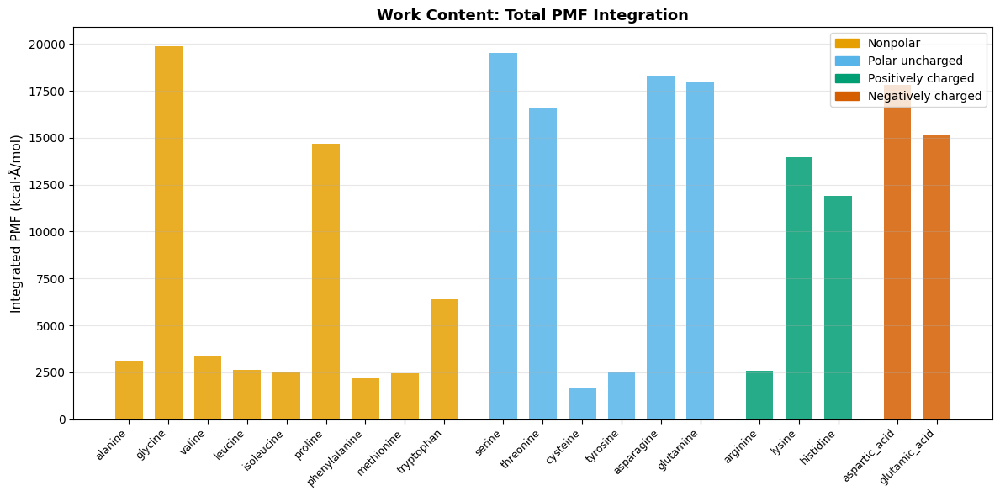


PMF SHAPE METRICS
Protein          Barrier Height     Barrier Pos     Integrated      Skewness    
----------------------------------------------------------------------------
alanine          476.87             35.00           3099.68         0.498       
arginine         449.21             35.00           2598.43         0.498       
asparagine       1629.83            35.00           18287.34        0.498       
aspartic_acid    1594.92            35.00           17835.36        0.498       
cysteine         309.30             35.00           1676.78         0.498       
glutamic_acid    1426.76            35.00           15128.10        0.498       
glutamine        1611.10            35.00           17933.23        0.498       
glycine          1731.74            35.00           19896.47        0.498       
histidine        1219.44            35.00           11920.54        0.498       
isoleucine       415.93             35.00           2502.70         0.498       
leucine      

In [105]:
# ============================================================
# DIFFERENTIAL PMF ANALYSIS — Compare proteins pairwise
# ============================================================
import numpy as np
from scipy.interpolate import interp1d
from scipy.integrate import trapezoid
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ── 1. Interpolate all PMFs to common extension grid ──
c_common = np.linspace(0, 35, 500)

pmf_dict = {}  # protein -> F2 on common grid
for protein in proteins:
    if protein not in results:
        continue
    r = results[protein]
    c_orig = r['c']
    F2_orig = r['F2'] - r['F2'][0]
    
    # Interpolate to common grid
    f_interp = interp1d(c_orig, F2_orig, kind='cubic', fill_value='extrapolate')
    F2_common = f_interp(c_common)
    F2_common[F2_common < 0] = 0  # clip negatives
    pmf_dict[protein] = F2_common

# ── 2. Compute pairwise PMF differences & similarity metrics ──
n_proteins = len(pmf_dict)
protein_list = list(pmf_dict.keys())

# Distance matrix: different metrics
euclidean_dist = np.zeros((n_proteins, n_proteins))
rmsd = np.zeros((n_proteins, n_proteins))
mae = np.zeros((n_proteins, n_proteins))  # mean absolute error
correlation = np.zeros((n_proteins, n_proteins))

for i, p1 in enumerate(protein_list):
    for j, p2 in enumerate(protein_list):
        F2_1 = pmf_dict[p1]
        F2_2 = pmf_dict[p2]
        
        # Euclidean distance
        euclidean_dist[i, j] = np.sqrt(np.sum((F2_1 - F2_2)**2))
        
        # RMSD
        rmsd[i, j] = np.sqrt(np.mean((F2_1 - F2_2)**2))
        
        # MAE
        mae[i, j] = np.mean(np.abs(F2_1 - F2_2))
        
        # Pearson correlation
        if np.std(F2_1) > 0 and np.std(F2_2) > 0:
            correlation[i, j] = np.corrcoef(F2_1, F2_2)[0, 1]
        else:
            correlation[i, j] = 0

# ── 3. Compute integrated PMF (area under curve) ──
integrated_pmf = {}
for protein in pmf_dict:
    integrated_pmf[protein] = trapezoid(pmf_dict[protein], c_common)

# ── 4. Visualize: Heatmaps of pairwise distances ──
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

metrics = [
    ('RMSD (kcal/mol)', rmsd),
    ('MAE (kcal/mol)', mae),
    ('Correlation (r)', correlation)
]

for ax, (title, data) in zip(axes, metrics):
    im = ax.imshow(data, cmap='RdYlGn_r' if 'Correlation' not in title else 'RdYlGn',
                   aspect='auto')
    ax.set_xticks(range(len(protein_list)))
    ax.set_yticks(range(len(protein_list)))
    ax.set_xticklabels(protein_list, rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(protein_list, fontsize=8)
    ax.set_title(title, fontsize=11, fontweight='bold')
    
    # Add text annotations
    for i in range(len(protein_list)):
        for j in range(len(protein_list)):
            text = ax.text(j, i, f'{data[i, j]:.2f}',
                          ha="center", va="center", color="black", fontsize=6)
    
    plt.colorbar(im, ax=ax)

plt.suptitle("Pairwise PMF Similarity Metrics", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_pairwise_distances.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 5. Group-level differential analysis ──
print("\n" + "="*80)
print("GROUP-LEVEL PMF COMPARISON")
print("="*80)

group_stats = {}
for group_name, members in groups.items():
    valid = [p for p in members if p in pmf_dict]
    if not valid:
        continue
    
    group_pmfs = np.array([pmf_dict[p] for p in valid])
    
    mean_pmf = np.mean(group_pmfs, axis=0)
    std_pmf = np.std(group_pmfs, axis=0)
    max_pmf = np.max(group_pmfs, axis=0)
    
    barrier_height = mean_pmf[-1] - mean_pmf[0]
    peak_idx = np.argmax(mean_pmf)
    barrier_pos = c_common[peak_idx]
    
    group_stats[group_name] = {
        'mean': mean_pmf,
        'std': std_pmf,
        'max': max_pmf,
        'barrier_height': barrier_height,
        'barrier_pos': barrier_pos,
        'members': valid,
    }
    
    print(f"\n{group_name}:")
    print(f"  Members: {', '.join(valid)}")
    print(f"  Mean barrier height: {barrier_height:.2f} ± {np.mean(std_pmf):.2f} kcal/mol")
    print(f"  Barrier position: {barrier_pos:.2f} Å")
    print(f"  Mean integrated PMF: {np.mean([integrated_pmf[p] for p in valid]):.2f} kcal·Å/mol")

# ── 6. Plot group-level comparison with error bands ──
fig, ax = plt.subplots(figsize=(12, 7))

for group_name in groups.keys():
    if group_name not in group_stats:
        continue
    gs = group_stats[group_name]
    color = group_colors[group_name]
    
    ax.plot(c_common, gs['mean'], lw=2.5, label=group_name, color=color)
    ax.fill_between(c_common, 
                     gs['mean'] - gs['std'], 
                     gs['mean'] + gs['std'],
                     alpha=0.2, color=color)

ax.set_xlabel("Extension (Å)", fontsize=12)
ax.set_ylabel("Mean PMF ± σ (kcal/mol)", fontsize=12)
ax.set_title("Group-averaged PMF Profiles with Standard Deviation", fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='upper left')
ax.grid(alpha=0.3)
ax.set_xlim(0, 35)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_group_comparison_with_std.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 7. Statistical comparison: group-wise ANOVA on barrier heights ──
from scipy.stats import f_oneway, kruskal

print("\n" + "="*80)
print("STATISTICAL TESTS")
print("="*80)

# Collect barrier heights per group
barrier_heights_by_group = {}
for group_name, members in groups.items():
    valid = [p for p in members if p in results]
    if valid:
        barrier_heights_by_group[group_name] = [results[p]['delta_F'] for p in valid]

# ANOVA
if len(barrier_heights_by_group) > 1:
    groups_data = list(barrier_heights_by_group.values())
    f_stat, p_val = f_oneway(*groups_data)
    print(f"\nOne-way ANOVA on barrier heights (ΔF) across groups:")
    print(f"  F-statistic: {f_stat:.4f}")
    print(f"  p-value: {p_val:.4e}")
    if p_val < 0.05:
        print(f"  ✓ Significant difference between groups (p < 0.05)")
    else:
        print(f"  ✗ No significant difference (p ≥ 0.05)")
    
    # Kruskal-Wallis (non-parametric alternative)
    h_stat, p_val_kw = kruskal(*groups_data)
    print(f"\nKruskal-Wallis test (non-parametric):")
    print(f"  H-statistic: {h_stat:.4f}")
    print(f"  p-value: {p_val_kw:.4e}")

# ── 8. Integrated PMF comparison ──
fig, ax = plt.subplots(figsize=(12, 6))

x_pos = 0
x_ticks, x_labels = [], []

for group_name, members in groups.items():
    valid = [p for p in members if p in integrated_pmf]
    for protein in valid:
        color = group_colors[group_name]
        ax.bar(x_pos, integrated_pmf[protein], color=color, alpha=0.85, width=0.7)
        x_ticks.append(x_pos)
        x_labels.append(protein)
        x_pos += 1
    x_pos += 0.5

ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel("Integrated PMF (kcal·Å/mol)", fontsize=11)
ax.set_title("Work Content: Total PMF Integration", fontsize=13, fontweight='bold')
legend_handles = [Patch(color=group_colors[g], label=g) for g in groups]
ax.legend(handles=legend_handles, fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f"{base_dir}/integrated_pmf_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 9. Compute shape metrics for each PMF ──
print("\n" + "="*80)
print("PMF SHAPE METRICS")
print("="*80)
print(f"{'Protein':<16} {'Barrier Height':<18} {'Barrier Pos':<15} {'Integrated':<15} {'Skewness':<12}")
print("-" * 76)

for protein in sorted(pmf_dict.keys()):
    F2 = pmf_dict[protein]
    
    # Barrier height
    barrier_h = F2[-1] - F2[0]
    
    # Barrier position (where max occurs)
    barrier_p = c_common[np.argmax(F2)]
    
    # Integrated area
    integrated = integrated_pmf[protein]
    
    # Skewness: distance from center to peak
    center = len(F2) // 2
    peak_idx = np.argmax(F2)
    skewness = (peak_idx - center) / len(F2)
    
    print(f"{protein:<16} {barrier_h:<18.2f} {barrier_p:<15.2f} {integrated:<15.2f} {skewness:<12.3f}")

print("\n Differential PMF analysis complete!")


LOCAL MINIMA IN PMF CURVES

Protein          Group                  # Minima     Positions (Å)                                      Energies (kcal/mol)      
----------------------------------------------------------------------------------------------------
alanine          Nonpolar               6            3.16, 8.63, 9.89, 12.27, 13.75, 14.45 1.99, 5.19, 5.40, 6.14, 6.15, 6.40
arginine         Positively charged     6            2.88, 3.30, 9.05, 11.36, 15.71, 20.62 1.62, 1.60, 9.92, 10.02, 17.21, 2.47
asparagine       Polar uncharged        0            None                           N/A                      
aspartic_acid    Negatively charged     0            None                           N/A                      
cysteine         Polar uncharged        8            1.68, 2.31, 4.84, 6.17, 6.66, 13.47, 15.57, 17.54 0.05, 0.26, 1.22, 1.28, 1.40, 1.38, 0.81, 2.70
glutamic_acid    Negatively charged     0            None                           N/A                      
glutam

/tmp/ipykernel_37376/1925766213.py:76: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



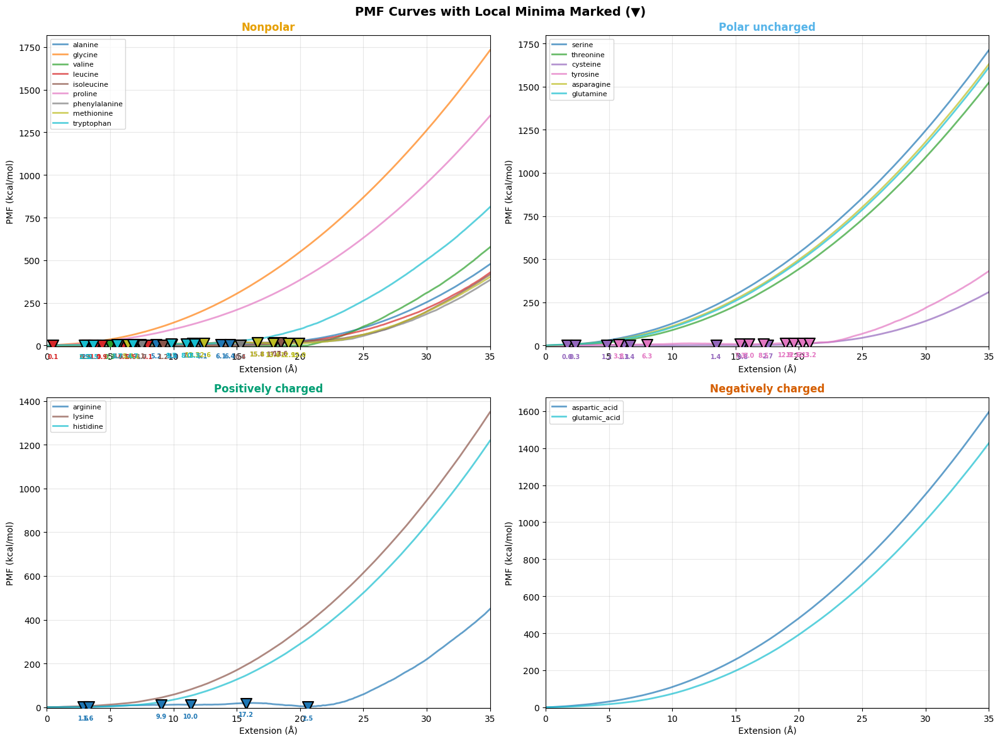

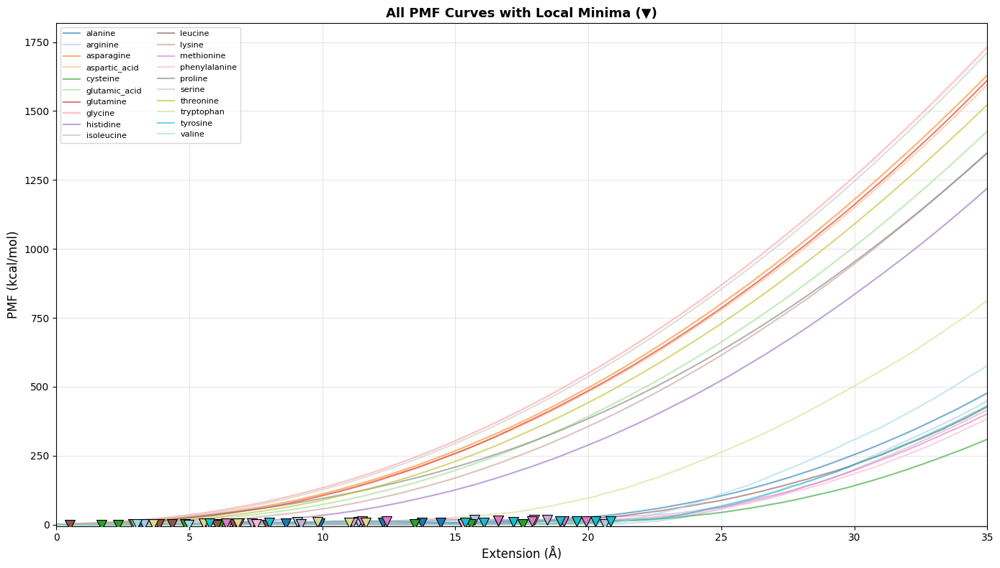


DETAILED LOCAL MINIMA ANALYSIS

All detected local minima:
      Protein              Group  Minimum #  Position (Å)  Energy (kcal/mol)
      alanine           Nonpolar          1      3.156313           1.989164
      alanine           Nonpolar          2      8.627255           5.193403
      alanine           Nonpolar          3      9.889780           5.401702
      alanine           Nonpolar          4     12.274549           6.135084
      alanine           Nonpolar          5     13.747495           6.147828
      alanine           Nonpolar          6     14.448898           6.396685
     arginine Positively charged          1      2.875752           1.615003
     arginine Positively charged          2      3.296593           1.599949
     arginine Positively charged          3      9.048096           9.916490
     arginine Positively charged          4     11.362725          10.021879
     arginine Positively charged          5     15.711423          17.211552
     arginine Po

In [106]:
# ============================================================
# LOCAL MINIMA DETECTION IN PMF CURVES
# ============================================================
from scipy.signal import argrelextrema
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd

# ── 1. Find all local minima for each protein ──
local_minima = {}

for protein in pmf_dict.keys():
    F2 = pmf_dict[protein]
    
    # Find local minima (order=5 means window of 11 points for smoothness)
    minima_idx = argrelextrema(F2, np.less, order=5)[0]
    
    # Get extension positions and energy values at minima
    minima_extensions = c_common[minima_idx]
    minima_energies = F2[minima_idx]
    
    local_minima[protein] = {
        'indices': minima_idx,
        'extensions': minima_extensions,
        'energies': minima_energies,
        'n_minima': len(minima_idx),
    }

# ── 2. Print summary table ──
print("\n" + "="*100)
print("LOCAL MINIMA IN PMF CURVES")
print("="*100)
print(f"\n{'Protein':<16} {'Group':<22} {'# Minima':<12} {'Positions (Å)':<50} {'Energies (kcal/mol)':<25}")
print("-" * 100)

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    group = get_group(protein)
    n_min = lm['n_minima']
    
    # Format positions and energies nicely
    if n_min > 0:
        pos_str = ', '.join([f"{x:.2f}" for x in lm['extensions']])
        eng_str = ', '.join([f"{e:.2f}" for e in lm['energies']])
    else:
        pos_str = "None"
        eng_str = "N/A"
    
    print(f"{protein:<16} {group:<22} {n_min:<12} {pos_str:<30} {eng_str:<25}")

# ── 3. Group-level statistics on minima ──
print("\n" + "="*100)
print("GROUP-LEVEL MINIMA STATISTICS")
print("="*100)

for group_name, members in groups.items():
    valid = [p for p in members if p in local_minima]
    if not valid:
        continue
    
    minima_counts = [local_minima[p]['n_minima'] for p in valid]
    proteins_with_minima = [p for p in valid if local_minima[p]['n_minima'] > 0]
    
    print(f"\n{group_name}:")
    print(f"  Members with local minima: {len(proteins_with_minima)}/{len(valid)}")
    print(f"  Mean # of minima: {np.mean(minima_counts):.2f}")
    print(f"  Max # of minima: {np.max(minima_counts)}")
    print(f"  Proteins with minima: {', '.join(proteins_with_minima) if proteins_with_minima else 'None'}")

# ── 4. Visualize PMF curves with marked local minima ──
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax_idx, (group_name, members) in enumerate(groups.items()):
    ax = axes[ax_idx]
    cmap = plt.cm.get_cmap('tab10', len(members))
    
    for j, protein in enumerate(members):
        if protein not in pmf_dict:
            continue
        
        F2 = pmf_dict[protein]
        color = cmap(j)
        
        # Plot PMF curve
        ax.plot(c_common, F2, lw=2, label=protein, color=color, alpha=0.7)
        
        # Mark local minima
        lm = local_minima[protein]
        if lm['n_minima'] > 0:
            ax.scatter(lm['extensions'], lm['energies'], 
                      color=color, s=150, marker='v', zorder=5, 
                      edgecolors='black', linewidth=1.5)
            
            # Annotate each minimum
            for x, e in zip(lm['extensions'], lm['energies']):
                ax.annotate(f'{e:.1f}', xy=(x, e), 
                           textcoords='offset points', xytext=(0, -15),
                           fontsize=7, ha='center', color=color, fontweight='bold')
    
    ax.set_title(f"{group_name}", fontsize=12, fontweight='bold',
                 color=group_colors[group_name])
    ax.set_xlabel("Extension (Å)")
    ax.set_ylabel("PMF (kcal/mol)")
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 35)
    ax.set_ylim(bottom=-5)

plt.suptitle("PMF Curves with Local Minima Marked (▼)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_local_minima.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 5. All proteins on single plot with minima highlighted ──
fig, ax = plt.subplots(figsize=(14, 8))

for protein, color in zip(sorted(pmf_dict.keys()), 
                         plt.cm.tab20(np.linspace(0, 1, len(pmf_dict)))):
    F2 = pmf_dict[protein]
    ax.plot(c_common, F2, lw=1.5, label=protein, color=color, alpha=0.6)
    
    # Mark minima
    lm = local_minima[protein]
    if lm['n_minima'] > 0:
        ax.scatter(lm['extensions'], lm['energies'], 
                  color=color, s=100, marker='v', zorder=4, edgecolors='black', linewidth=0.8)

ax.set_xlabel("Extension (Å)", fontsize=12)
ax.set_ylabel("PMF (kcal/mol)", fontsize=12)
ax.set_title("All PMF Curves with Local Minima (▼)", fontsize=13, fontweight='bold')
ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.grid(alpha=0.3)
ax.set_xlim(0, 35)
ax.set_ylim(bottom=-5)
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_all_with_minima.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 6. Detailed minima analysis table ──
print("\n" + "="*100)
print("DETAILED LOCAL MINIMA ANALYSIS")
print("="*100)

minima_data = []

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    if lm['n_minima'] > 0:
        for i, (ext, eng) in enumerate(zip(lm['extensions'], lm['energies']), 1):
            minima_data.append({
                'Protein': protein,
                'Group': get_group(protein),
                'Minimum #': i,
                'Position (Å)': ext,
                'Energy (kcal/mol)': eng,
            })

if minima_data:
    df_minima = pd.DataFrame(minima_data)
    print("\nAll detected local minima:")
    print(df_minima.to_string(index=False))
    
    # Statistics by group
    print(f"\n\nSummary by group:")
    for group_name in groups.keys():
        group_minima = df_minima[df_minima['Group'] == group_name]
        if len(group_minima) > 0:
            print(f"\n{group_name}:")
            print(f"  Total minima: {len(group_minima)}")
            print(f"  Mean position: {group_minima['Position (Å)'].mean():.2f} Å")
            print(f"  Mean energy: {group_minima['Energy (kcal/mol)'].mean():.2f} kcal/mol")
            print(f"  Position range: {group_minima['Position (Å)'].min():.2f} - {group_minima['Position (Å)'].max():.2f} Å")
else:
    print("\nNo local minima detected in any PMF curves!")

# ── 7. Barrier shape classification ──
print("\n" + "="*100)
print("PMF SHAPE CLASSIFICATION")
print("="*100)

shape_classes = {'Single barrier': [], 'Double barrier': [], 'Multi-barrier': [], 'No minima': []}

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    n_min = lm['n_minima']
    
    if n_min == 0:
        shape_classes['Single barrier'].append(protein)
    elif n_min == 1:
        shape_classes['Double barrier'].append(protein)
    else:
        shape_classes['Multi-barrier'].append(protein)

print("\nPMF shape distribution:")
for shape, proteins_list in shape_classes.items():
    count = len(proteins_list)
    pct = 100 * count / len(pmf_dict)
    print(f"\n{shape}: {count} proteins ({pct:.1f}%)")
    if proteins_list:
        print(f"  {', '.join(proteins_list)}")

print("\n Local minima analysis complete!")


LOCAL MINIMA IN PMF CURVES — WITH DEPTH ANALYSIS

Protein          Group                  # Minima     Positions (Å)                            Energies (kcal/mol)                 Depths (kcal/mol)                  
----------------------------------------------------------------------------------------------------------------------------------
alanine          Nonpolar               6            3.16, 8.63, 9.89, 12.27, 13.75, 14.45    1.99, 5.19, 5.40, 6.14, 6.15, 6.40  237.50, 236.11, 235.93, 235.57, 235.62, 235.38
arginine         Positively charged     6            2.88, 3.30, 9.05, 11.36, 15.71, 20.62    1.62, 1.60, 9.92, 10.02, 17.21, 2.47 224.07, 224.08, 219.91, 220.42, 216.32, 231.69
asparagine       Polar uncharged        0            None                                     N/A                                 N/A                                
aspartic_acid    Negatively charged     0            None                                     N/A                                 N

/tmp/ipykernel_37376/1071588635.py:170: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



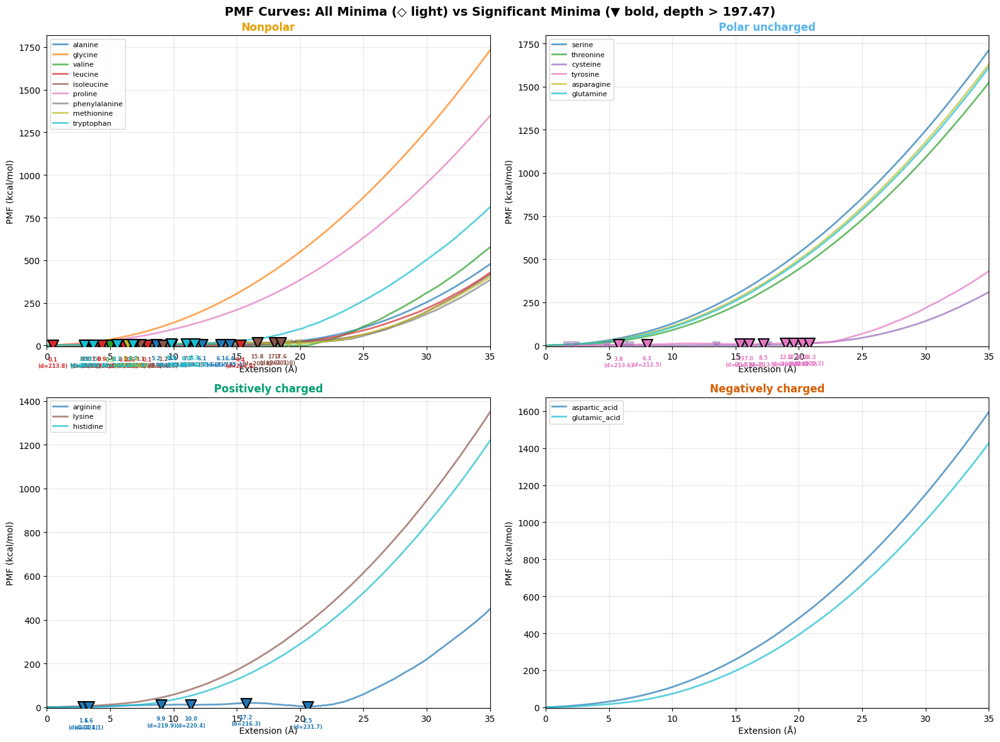

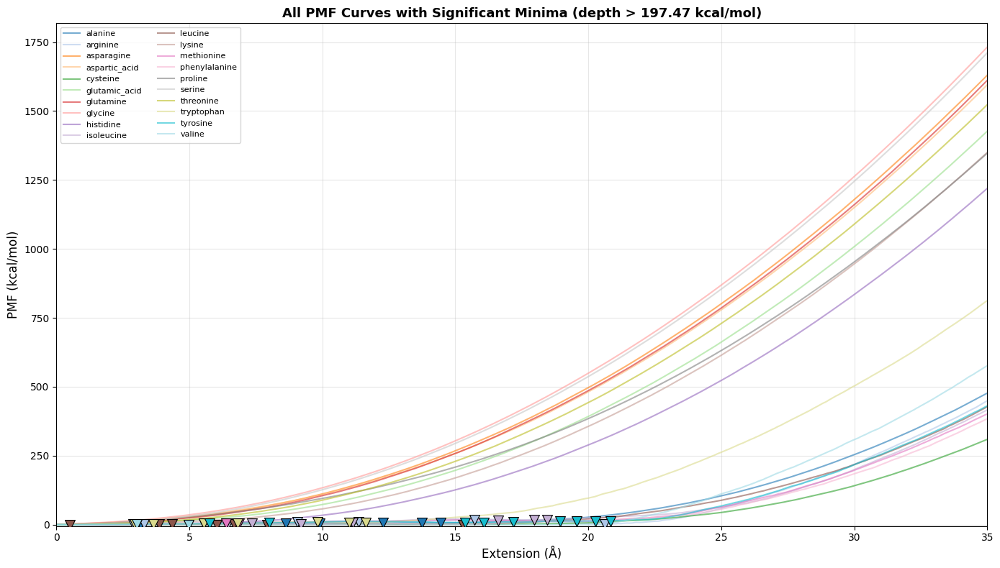


DETAILED ANALYSIS — SIGNIFICANT LOCAL MINIMA ONLY

All significant local minima:
   Protein              Group  Min # Position (Å) Energy (kcal/mol) Depth (kcal/mol)
   alanine           Nonpolar      1         3.16              1.99           237.50
   alanine           Nonpolar      2         8.63              5.19           236.11
   alanine           Nonpolar      3         9.89              5.40           235.93
   alanine           Nonpolar      4        12.27              6.14           235.57
   alanine           Nonpolar      5        13.75              6.15           235.62
   alanine           Nonpolar      6        14.45              6.40           235.38
  arginine Positively charged      1         2.88              1.62           224.07
  arginine Positively charged      2         3.30              1.60           224.08
  arginine Positively charged      3         9.05              9.92           219.91
  arginine Positively charged      4        11.36             10.02 

In [107]:
# ============================================================
# LOCAL MINIMA DETECTION IN PMF CURVES — WITH DEPTH ANALYSIS
# ============================================================
from scipy.signal import argrelextrema
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd

# ── 1. Find all local minima with depth calculation ──
local_minima = {}

for protein in pmf_dict.keys():
    F2 = pmf_dict[protein]
    
    # Find local minima (order=5 means window of 11 points for smoothness)
    minima_idx = argrelextrema(F2, np.less, order=5)[0]
    
    # Get extension positions and energy values at minima
    minima_extensions = c_common[minima_idx]
    minima_energies = F2[minima_idx]
    
    # Calculate depth: how much lower is the minimum compared to surrounding peaks
    minima_depths = []
    for idx in minima_idx:
        # Find the two nearest peaks (local maxima) on either side
        left_peak = F2[:idx].max() if idx > 0 else F2[idx]
        right_peak = F2[idx:].max() if idx < len(F2)-1 else F2[idx]
        
        # Depth = average of surrounding peaks minus the minimum value
        surrounding_avg = (left_peak + right_peak) / 2
        depth = surrounding_avg - F2[idx]
        minima_depths.append(depth)
    
    minima_depths = np.array(minima_depths)
    
    local_minima[protein] = {
        'indices': minima_idx,
        'extensions': minima_extensions,
        'energies': minima_energies,
        'depths': minima_depths,
        'n_minima': len(minima_idx),
    }

# ── 2. Print summary table with depth threshold ──
print("\n" + "="*130)
print("LOCAL MINIMA IN PMF CURVES — WITH DEPTH ANALYSIS")
print("="*130)
print(f"\n{'Protein':<16} {'Group':<22} {'# Minima':<12} {'Positions (Å)':<40} {'Energies (kcal/mol)':<35} {'Depths (kcal/mol)':<35}")
print("-" * 130)

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    group = get_group(protein)
    n_min = lm['n_minima']
    
    # Format positions, energies, and depths with more space
    if n_min > 0:
        pos_str = ', '.join([f"{x:.2f}" for x in lm['extensions']])
        eng_str = ', '.join([f"{e:.2f}" for e in lm['energies']])
        dep_str = ', '.join([f"{d:.2f}" for d in lm['depths']])
    else:
        pos_str = "None"
        eng_str = "N/A"
        dep_str = "N/A"
    
    print(f"{protein:<16} {group:<22} {n_min:<12} {pos_str:<40} {eng_str:<35} {dep_str:<35}")

# ── 3. Depth threshold analysis ──
print("\n" + "="*130)
print("MINIMA DEPTH THRESHOLD ANALYSIS")
print("="*130)

# Collect all depths
all_depths = []
for protein in local_minima:
    all_depths.extend(local_minima[protein]['depths'])

if all_depths:
    all_depths = np.array(all_depths)
    depth_threshold = np.percentile(all_depths, 25)  # 25th percentile as threshold
    
    print(f"\nDepth Statistics (all minima across all proteins):")
    print(f"  Mean depth: {np.mean(all_depths):.3f} kcal/mol")
    print(f"  Median depth: {np.median(all_depths):.3f} kcal/mol")
    print(f"  Std dev: {np.std(all_depths):.3f} kcal/mol")
    print(f"  Min depth: {np.min(all_depths):.3f} kcal/mol")
    print(f"  Max depth: {np.max(all_depths):.3f} kcal/mol")
    print(f"\n  Suggested depth threshold (25th percentile): {depth_threshold:.3f} kcal/mol")
    print(f"  (minima with depth < threshold are likely noise)")
else:
    depth_threshold = 0
    print("No minima detected")

# ── 4. Filter minima by depth ──
print("\n" + "="*130)
print("SIGNIFICANT MINIMA (depth > threshold)")
print("="*130)

significant_minima = {}
for protein in local_minima:
    lm = local_minima[protein]
    
    # Keep only minima with significant depth
    if lm['n_minima'] > 0:
        sig_mask = lm['depths'] > depth_threshold
        sig_idx = lm['indices'][sig_mask]
        sig_ext = lm['extensions'][sig_mask]
        sig_eng = lm['energies'][sig_mask]
        sig_dep = lm['depths'][sig_mask]
    else:
        sig_idx = np.array([])
        sig_ext = np.array([])
        sig_eng = np.array([])
        sig_dep = np.array([])
    
    significant_minima[protein] = {
        'indices': sig_idx,
        'extensions': sig_ext,
        'energies': sig_eng,
        'depths': sig_dep,
        'n_minima': len(sig_idx),
    }

print(f"\n{'Protein':<16} {'Group':<22} {'# Significant':<18} {'Positions (Å)':<40} {'Depths (kcal/mol)':<35}")
print("-" * 130)

for protein in sorted(significant_minima.keys()):
    sm = significant_minima[protein]
    group = get_group(protein)
    n_sig = sm['n_minima']
    
    if n_sig > 0:
        pos_str = ', '.join([f"{x:.2f}" for x in sm['extensions']])
        dep_str = ', '.join([f"{d:.2f}" for d in sm['depths']])
    else:
        pos_str = "None"
        dep_str = "N/A"
    
    print(f"{protein:<16} {group:<22} {n_sig:<18} {pos_str:<40} {dep_str:<35}")

# ── 5. Group-level statistics on minima ──
print("\n" + "="*130)
print("GROUP-LEVEL MINIMA STATISTICS")
print("="*130)

for group_name, members in groups.items():
    valid = [p for p in members if p in local_minima]
    if not valid:
        continue
    
    total_minima = sum([local_minima[p]['n_minima'] for p in valid])
    significant_count = sum([significant_minima[p]['n_minima'] for p in valid])
    proteins_with_minima = [p for p in valid if local_minima[p]['n_minima'] > 0]
    proteins_sig = [p for p in valid if significant_minima[p]['n_minima'] > 0]
    
    print(f"\n{group_name}:")
    print(f"  Members with local minima: {len(proteins_with_minima)}/{len(valid)}")
    print(f"  Members with SIGNIFICANT minima: {len(proteins_sig)}/{len(valid)}")
    print(f"  Total minima (all): {total_minima}")
    print(f"  Total SIGNIFICANT minima: {significant_count}")
    print(f"  Mean # of minima per protein: {np.mean([local_minima[p]['n_minima'] for p in valid]):.2f}")
    print(f"  Mean depth of significant minima: {np.mean([d for p in proteins_sig for d in significant_minima[p]['depths']]):.3f} kcal/mol" if proteins_sig else "  N/A")

# ── 6. Visualize PMF curves with marked local minima (colored by depth) ──
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax_idx, (group_name, members) in enumerate(groups.items()):
    ax = axes[ax_idx]
    cmap = plt.cm.get_cmap('tab10', len(members))
    
    for j, protein in enumerate(members):
        if protein not in pmf_dict:
            continue
        
        F2 = pmf_dict[protein]
        color = cmap(j)
        
        # Plot PMF curve
        ax.plot(c_common, F2, lw=2, label=protein, color=color, alpha=0.7)
        
        # Mark ALL local minima (light markers)
        lm = local_minima[protein]
        if lm['n_minima'] > 0:
            ax.scatter(lm['extensions'], lm['energies'], 
                      color=color, s=80, marker='v', zorder=4, 
                      edgecolors='gray', linewidth=0.8, alpha=0.5, label='_nolegend_')
        
        # Mark SIGNIFICANT minima (bold markers)
        sm = significant_minima[protein]
        if sm['n_minima'] > 0:
            ax.scatter(sm['extensions'], sm['energies'], 
                      color=color, s=150, marker='v', zorder=5, 
                      edgecolors='black', linewidth=1.5)
            
            # Annotate significant minima only
            for x, e, d in zip(sm['extensions'], sm['energies'], sm['depths']):
                ax.annotate(f'{e:.1f}\n(d={d:.1f})', xy=(x, e), 
                           textcoords='offset points', xytext=(0, -25),
                           fontsize=6, ha='center', color=color, fontweight='bold')
    
    ax.set_title(f"{group_name}", fontsize=12, fontweight='bold',
                 color=group_colors[group_name])
    ax.set_xlabel("Extension (Å)")
    ax.set_ylabel("PMF (kcal/mol)")
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 35)
    ax.set_ylim(bottom=-5)

plt.suptitle(f"PMF Curves: All Minima (◇ light) vs Significant Minima (▼ bold, depth > {depth_threshold:.2f})", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_local_minima_with_depth.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 7. All proteins on single plot ──
fig, ax = plt.subplots(figsize=(14, 8))

for protein, color in zip(sorted(pmf_dict.keys()), 
                         plt.cm.tab20(np.linspace(0, 1, len(pmf_dict)))):
    F2 = pmf_dict[protein]
    ax.plot(c_common, F2, lw=1.5, label=protein, color=color, alpha=0.6)
    
    # Mark significant minima only
    sm = significant_minima[protein]
    if sm['n_minima'] > 0:
        ax.scatter(sm['extensions'], sm['energies'], 
                  color=color, s=100, marker='v', zorder=4, edgecolors='black', linewidth=0.8)

ax.set_xlabel("Extension (Å)", fontsize=12)
ax.set_ylabel("PMF (kcal/mol)", fontsize=12)
ax.set_title(f"All PMF Curves with Significant Minima (depth > {depth_threshold:.2f} kcal/mol)", 
             fontsize=13, fontweight='bold')
ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.grid(alpha=0.3)
ax.set_xlim(0, 35)
ax.set_ylim(bottom=-5)
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_all_significant_minima.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 8. Detailed minima analysis table (significant only) ──
print("\n" + "="*130)
print("DETAILED ANALYSIS — SIGNIFICANT LOCAL MINIMA ONLY")
print("="*130)

minima_data = []

for protein in sorted(significant_minima.keys()):
    sm = significant_minima[protein]
    if sm['n_minima'] > 0:
        for i, (ext, eng, dep) in enumerate(zip(sm['extensions'], sm['energies'], sm['depths']), 1):
            minima_data.append({
                'Protein': protein,
                'Group': get_group(protein),
                'Min #': i,
                'Position (Å)': f"{ext:.2f}",
                'Energy (kcal/mol)': f"{eng:.2f}",
                'Depth (kcal/mol)': f"{dep:.2f}",
            })

if minima_data:
    df_minima = pd.DataFrame(minima_data)
    print("\nAll significant local minima:")
    print(df_minima.to_string(index=False))
    
    # Statistics by group
    print(f"\n\nSummary by group (significant minima only):")
    for group_name in groups.keys():
        group_minima = df_minima[df_minima['Group'] == group_name]
        if len(group_minima) > 0:
            print(f"\n{group_name}:")
            print(f"  Total significant minima: {len(group_minima)}")
            depths = [float(x) for x in group_minima['Depth (kcal/mol)']]
            positions = [float(x) for x in group_minima['Position (Å)']]
            print(f"  Mean depth: {np.mean(depths):.3f} kcal/mol")
            print(f"  Mean position: {np.mean(positions):.2f} Å")
            print(f"  Depth range: {np.min(depths):.3f} - {np.max(depths):.3f} kcal/mol")
            print(f"  Position range: {np.min(positions):.2f} - {np.max(positions):.2f} Å")
else:
    print("\nNo significant local minima detected!")

# ── 9. Barrier shape classification (using significant minima) ──
print("\n" + "="*130)
print("PMF SHAPE CLASSIFICATION (based on significant minima)")
print("="*130)

shape_classes = {'Single barrier': [], 'Double barrier': [], 'Multi-barrier': [], 'No minima': []}

for protein in sorted(significant_minima.keys()):
    sm = significant_minima[protein]
    n_min = sm['n_minima']
    
    if n_min == 0:
        shape_classes['Single barrier'].append(protein)
    elif n_min == 1:
        shape_classes['Double barrier'].append(protein)
    else:
        shape_classes['Multi-barrier'].append(protein)

print("\nPMF shape distribution:")
for shape, proteins_list in shape_classes.items():
    count = len(proteins_list)
    pct = 100 * count / len(pmf_dict)
    print(f"\n{shape}: {count} proteins ({pct:.1f}%)")
    if proteins_list:
        print(f"  {', '.join(proteins_list)}")

print("\n✓ Local minima analysis with depth filtering complete!")


LOCAL MINIMA IN PMF CURVES — DEPTH RELATIVE TO PRECEDING PEAK

Protein          Group                  # Minima     Positions (Å)                                 Energies (kcal/mol)                      Depths to Left Peak                     
------------------------------------------------------------------------------------------------------------------------------------------------------
alanine          Nonpolar               6            3.16, 8.63, 9.89, 12.27, 13.75, 14.45         1.99, 5.19, 5.40, 6.14, 6.15, 6.40       0.11, 0.53, 0.39, 0.39, 0.52, 0.27      
arginine         Positively charged     6            2.88, 3.30, 9.05, 11.36, 15.71, 20.62         1.62, 1.60, 9.92, 10.02, 17.21, 2.47     0.53, 0.55, 0.52, 1.66, 0.64, 16.64     
asparagine       Polar uncharged        0            None                                          N/A                                      N/A                                     
aspartic_acid    Negatively charged     0            None    

/tmp/ipykernel_37376/1688458873.py:172: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



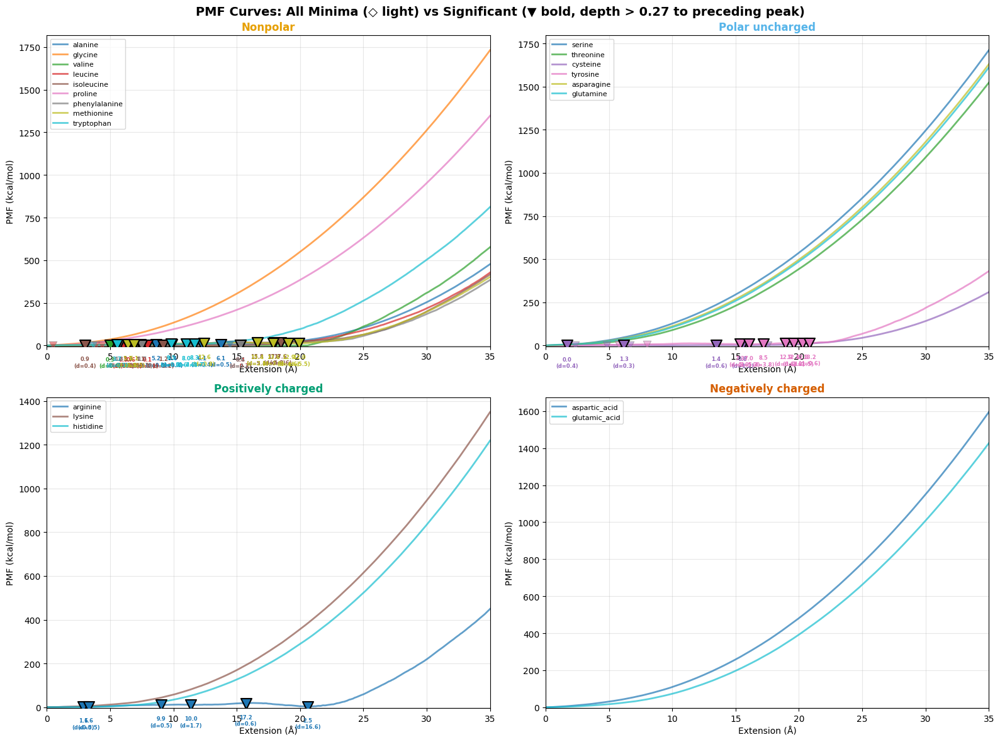

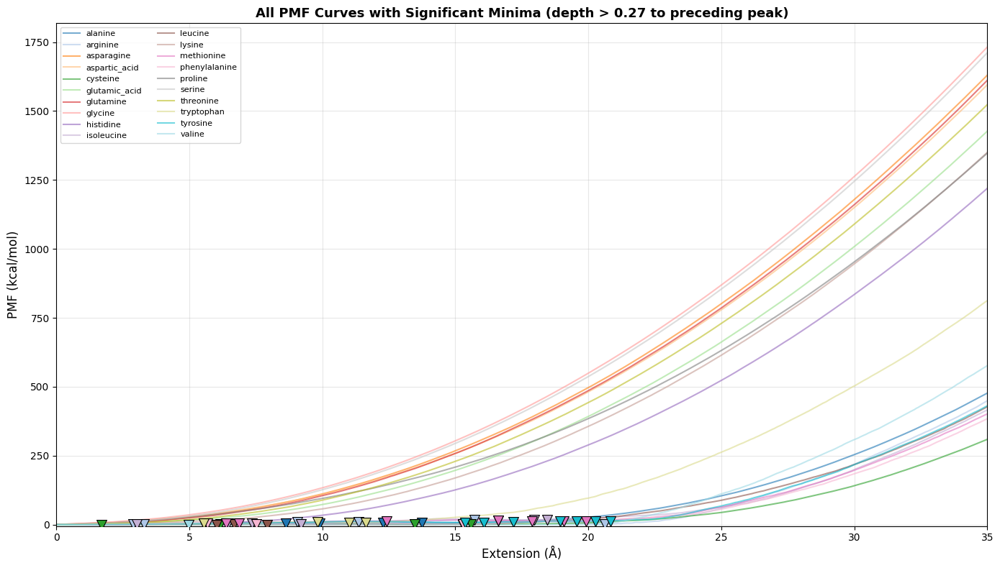


DETAILED ANALYSIS — SIGNIFICANT LOCAL MINIMA ONLY

All significant local minima:
      Protein              Group  Min # Position (Å) Energy (kcal/mol) Depth to Left Peak (kcal/mol)
      alanine           Nonpolar      1         8.63              5.19                          0.53
      alanine           Nonpolar      2         9.89              5.40                          0.39
      alanine           Nonpolar      3        12.27              6.14                          0.39
      alanine           Nonpolar      4        13.75              6.15                          0.52
     arginine Positively charged      1         2.88              1.62                          0.53
     arginine Positively charged      2         3.30              1.60                          0.55
     arginine Positively charged      3         9.05              9.92                          0.52
     arginine Positively charged      4        11.36             10.02                          1.66
     argi

In [108]:
# ============================================================
# LOCAL MINIMA DETECTION — DEPTH RELATIVE TO PRECEDING PEAK
# ============================================================
from scipy.signal import argrelextrema
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd

# ── 1. Find all local minima with depth calculation ──
local_minima = {}

for protein in pmf_dict.keys():
    F2 = pmf_dict[protein]
    
    # Find local minima (order=5 means window of 11 points for smoothness)
    minima_idx = argrelextrema(F2, np.less, order=5)[0]
    
    # Get extension positions and energy values at minima
    minima_extensions = c_common[minima_idx]
    minima_energies = F2[minima_idx]
    
    # Calculate depth relative to the PRECEDING PEAK only
    minima_depths = []
    for idx in minima_idx:
        # Find the maximum value BEFORE this minimum
        if idx > 0:
            left_peak = F2[:idx].max()
        else:
            left_peak = F2[idx]  # fallback if at start
        
        # Depth = preceding peak minus the minimum value
        depth = left_peak - F2[idx]
        minima_depths.append(depth)
    
    minima_depths = np.array(minima_depths)
    
    local_minima[protein] = {
        'indices': minima_idx,
        'extensions': minima_extensions,
        'energies': minima_energies,
        'depths': minima_depths,
        'n_minima': len(minima_idx),
    }

# ── 2. Print summary table with depth threshold ──
print("\n" + "="*150)
print("LOCAL MINIMA IN PMF CURVES — DEPTH RELATIVE TO PRECEDING PEAK")
print("="*150)
print(f"\n{'Protein':<16} {'Group':<22} {'# Minima':<12} {'Positions (Å)':<45} {'Energies (kcal/mol)':<40} {'Depths to Left Peak':<40}")
print("-" * 150)

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    group = get_group(protein)
    n_min = lm['n_minima']
    
    # Format positions, energies, and depths with more space
    if n_min > 0:
        pos_str = ', '.join([f"{x:.2f}" for x in lm['extensions']])
        eng_str = ', '.join([f"{e:.2f}" for e in lm['energies']])
        dep_str = ', '.join([f"{d:.2f}" for d in lm['depths']])
    else:
        pos_str = "None"
        eng_str = "N/A"
        dep_str = "N/A"
    
    print(f"{protein:<16} {group:<22} {n_min:<12} {pos_str:<45} {eng_str:<40} {dep_str:<40}")

# ── 3. Depth threshold analysis ──
print("\n" + "="*150)
print("MINIMA DEPTH THRESHOLD ANALYSIS (Relative to Preceding Peak)")
print("="*150)

# Collect all depths
all_depths = []
for protein in local_minima:
    all_depths.extend(local_minima[protein]['depths'])

if all_depths:
    all_depths = np.array(all_depths)
    depth_threshold = np.percentile(all_depths, 25)  # 25th percentile as threshold
    
    print(f"\nDepth Statistics (all minima across all proteins):")
    print(f"  Mean depth: {np.mean(all_depths):.3f} kcal/mol")
    print(f"  Median depth: {np.median(all_depths):.3f} kcal/mol")
    print(f"  Std dev: {np.std(all_depths):.3f} kcal/mol")
    print(f"  Min depth: {np.min(all_depths):.3f} kcal/mol")
    print(f"  Max depth: {np.max(all_depths):.3f} kcal/mol")
    print(f"\n  Suggested depth threshold (25th percentile): {depth_threshold:.3f} kcal/mol")
    print(f"  (minima with depth < threshold are likely noise)")
else:
    depth_threshold = 0
    print("No minima detected")

# ── 4. Filter minima by depth ──
print("\n" + "="*150)
print("SIGNIFICANT MINIMA (depth > threshold)")
print("="*150)

significant_minima = {}
for protein in local_minima:
    lm = local_minima[protein]
    
    # Keep only minima with significant depth
    if lm['n_minima'] > 0:
        sig_mask = lm['depths'] > depth_threshold
        sig_idx = lm['indices'][sig_mask]
        sig_ext = lm['extensions'][sig_mask]
        sig_eng = lm['energies'][sig_mask]
        sig_dep = lm['depths'][sig_mask]
    else:
        sig_idx = np.array([])
        sig_ext = np.array([])
        sig_eng = np.array([])
        sig_dep = np.array([])
    
    significant_minima[protein] = {
        'indices': sig_idx,
        'extensions': sig_ext,
        'energies': sig_eng,
        'depths': sig_dep,
        'n_minima': len(sig_idx),
    }

print(f"\n{'Protein':<16} {'Group':<22} {'# Significant':<18} {'Positions (Å)':<45} {'Depths to Left Peak':<40}")
print("-" * 150)

for protein in sorted(significant_minima.keys()):
    sm = significant_minima[protein]
    group = get_group(protein)
    n_sig = sm['n_minima']
    
    if n_sig > 0:
        pos_str = ', '.join([f"{x:.2f}" for x in sm['extensions']])
        dep_str = ', '.join([f"{d:.2f}" for d in sm['depths']])
    else:
        pos_str = "None"
        dep_str = "N/A"
    
    print(f"{protein:<16} {group:<22} {n_sig:<18} {pos_str:<45} {dep_str:<40}")

# ── 5. Group-level statistics on minima ──
print("\n" + "="*150)
print("GROUP-LEVEL MINIMA STATISTICS")
print("="*150)

for group_name, members in groups.items():
    valid = [p for p in members if p in local_minima]
    if not valid:
        continue
    
    total_minima = sum([local_minima[p]['n_minima'] for p in valid])
    significant_count = sum([significant_minima[p]['n_minima'] for p in valid])
    proteins_with_minima = [p for p in valid if local_minima[p]['n_minima'] > 0]
    proteins_sig = [p for p in valid if significant_minima[p]['n_minima'] > 0]
    
    print(f"\n{group_name}:")
    print(f"  Members with local minima: {len(proteins_with_minima)}/{len(valid)}")
    print(f"  Members with SIGNIFICANT minima: {len(proteins_sig)}/{len(valid)}")
    print(f"  Total minima (all): {total_minima}")
    print(f"  Total SIGNIFICANT minima: {significant_count}")
    print(f"  Mean # of minima per protein: {np.mean([local_minima[p]['n_minima'] for p in valid]):.2f}")
    if proteins_sig:
        print(f"  Mean depth of significant minima: {np.mean([d for p in proteins_sig for d in significant_minima[p]['depths']]):.3f} kcal/mol")

# ── 6. Visualize PMF curves with marked local minima (colored by depth) ──
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax_idx, (group_name, members) in enumerate(groups.items()):
    ax = axes[ax_idx]
    cmap = plt.cm.get_cmap('tab10', len(members))
    
    for j, protein in enumerate(members):
        if protein not in pmf_dict:
            continue
        
        F2 = pmf_dict[protein]
        color = cmap(j)
        
        # Plot PMF curve
        ax.plot(c_common, F2, lw=2, label=protein, color=color, alpha=0.7)
        
        # Mark ALL local minima (light markers)
        lm = local_minima[protein]
        if lm['n_minima'] > 0:
            ax.scatter(lm['extensions'], lm['energies'], 
                      color=color, s=80, marker='v', zorder=4, 
                      edgecolors='gray', linewidth=0.8, alpha=0.5, label='_nolegend_')
        
        # Mark SIGNIFICANT minima (bold markers)
        sm = significant_minima[protein]
        if sm['n_minima'] > 0:
            ax.scatter(sm['extensions'], sm['energies'], 
                      color=color, s=150, marker='v', zorder=5, 
                      edgecolors='black', linewidth=1.5)
            
            # Annotate significant minima only
            for x, e, d in zip(sm['extensions'], sm['energies'], sm['depths']):
                ax.annotate(f'{e:.1f}\n(d={d:.1f})', xy=(x, e), 
                           textcoords='offset points', xytext=(0, -25),
                           fontsize=6, ha='center', color=color, fontweight='bold')
    
    ax.set_title(f"{group_name}", fontsize=12, fontweight='bold',
                 color=group_colors[group_name])
    ax.set_xlabel("Extension (Å)")
    ax.set_ylabel("PMF (kcal/mol)")
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 35)
    ax.set_ylim(bottom=-5)

plt.suptitle(f"PMF Curves: All Minima (◇ light) vs Significant (▼ bold, depth > {depth_threshold:.2f} to preceding peak)", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_local_minima_with_depth.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 7. All proteins on single plot ──
fig, ax = plt.subplots(figsize=(14, 8))

for protein, color in zip(sorted(pmf_dict.keys()), 
                         plt.cm.tab20(np.linspace(0, 1, len(pmf_dict)))):
    F2 = pmf_dict[protein]
    ax.plot(c_common, F2, lw=1.5, label=protein, color=color, alpha=0.6)
    
    # Mark significant minima only
    sm = significant_minima[protein]
    if sm['n_minima'] > 0:
        ax.scatter(sm['extensions'], sm['energies'], 
                  color=color, s=100, marker='v', zorder=4, edgecolors='black', linewidth=0.8)

ax.set_xlabel("Extension (Å)", fontsize=12)
ax.set_ylabel("PMF (kcal/mol)", fontsize=12)
ax.set_title(f"All PMF Curves with Significant Minima (depth > {depth_threshold:.2f} to preceding peak)", 
             fontsize=13, fontweight='bold')
ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.grid(alpha=0.3)
ax.set_xlim(0, 35)
ax.set_ylim(bottom=-5)
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_all_significant_minima.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 8. Detailed minima analysis table (significant only) ──
print("\n" + "="*150)
print("DETAILED ANALYSIS — SIGNIFICANT LOCAL MINIMA ONLY")
print("="*150)

minima_data = []

for protein in sorted(significant_minima.keys()):
    sm = significant_minima[protein]
    if sm['n_minima'] > 0:
        for i, (ext, eng, dep) in enumerate(zip(sm['extensions'], sm['energies'], sm['depths']), 1):
            minima_data.append({
                'Protein': protein,
                'Group': get_group(protein),
                'Min #': i,
                'Position (Å)': f"{ext:.2f}",
                'Energy (kcal/mol)': f"{eng:.2f}",
                'Depth to Left Peak (kcal/mol)': f"{dep:.2f}",
            })

if minima_data:
    df_minima = pd.DataFrame(minima_data)
    print("\nAll significant local minima:")
    print(df_minima.to_string(index=False))
    
    # Statistics by group
    print(f"\n\nSummary by group (significant minima only):")
    for group_name in groups.keys():
        group_minima = df_minima[df_minima['Group'] == group_name]
        if len(group_minima) > 0:
            print(f"\n{group_name}:")
            print(f"  Total significant minima: {len(group_minima)}")
            depths = [float(x) for x in group_minima['Depth to Left Peak (kcal/mol)']]
            positions = [float(x) for x in group_minima['Position (Å)']]
            print(f"  Mean depth: {np.mean(depths):.3f} kcal/mol")
            print(f"  Mean position: {np.mean(positions):.2f} Å")
            print(f"  Depth range: {np.min(depths):.3f} - {np.max(depths):.3f} kcal/mol")
            print(f"  Position range: {np.min(positions):.2f} - {np.max(positions):.2f} Å")
else:
    print("\nNo significant local minima detected!")

# ── 9. Barrier shape classification (using significant minima) ──
print("\n" + "="*150)
print("PMF SHAPE CLASSIFICATION (based on significant minima)")
print("="*150)

shape_classes = {'Single barrier': [], 'Double barrier': [], 'Multi-barrier': [], 'No minima': []}

for protein in sorted(significant_minima.keys()):
    sm = significant_minima[protein]
    n_min = sm['n_minima']
    
    if n_min == 0:
        shape_classes['Single barrier'].append(protein)
    elif n_min == 1:
        shape_classes['Double barrier'].append(protein)
    else:
        shape_classes['Multi-barrier'].append(protein)

print("\nPMF shape distribution:")
for shape, proteins_list in shape_classes.items():
    count = len(proteins_list)
    pct = 100 * count / len(pmf_dict)
    print(f"\n{shape}: {count} proteins ({pct:.1f}%)")
    if proteins_list:
        print(f"  {', '.join(proteins_list)}")

print("\n✓ Local minima analysis with depth filtering complete!")


LOCAL MINIMA IN PMF CURVES — WITH VARIANCE ANALYSIS (Until Last Minima)

Protein          Group                  # Min    Last Min (Å)   Var Until        Var After        Ratio        Positions                                    
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
alanine          Nonpolar               6        14.45          3.8966           19448.7631       4991.243     3.16, 8.63, 9.89, 12.27, 13.75, 14.45        
arginine         Positively charged     6        20.62          28.7023          18452.6720       642.900      2.88, 3.30, 9.05, 11.36, 15.71, 20.62        
asparagine       Polar uncharged        0        N/A            236458.5758      0.0000           0.000        None                                         
aspartic_acid    Negatively charged     0        N/A            224809.5635      0.0000          

/tmp/ipykernel_37376/4184888079.py:240: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



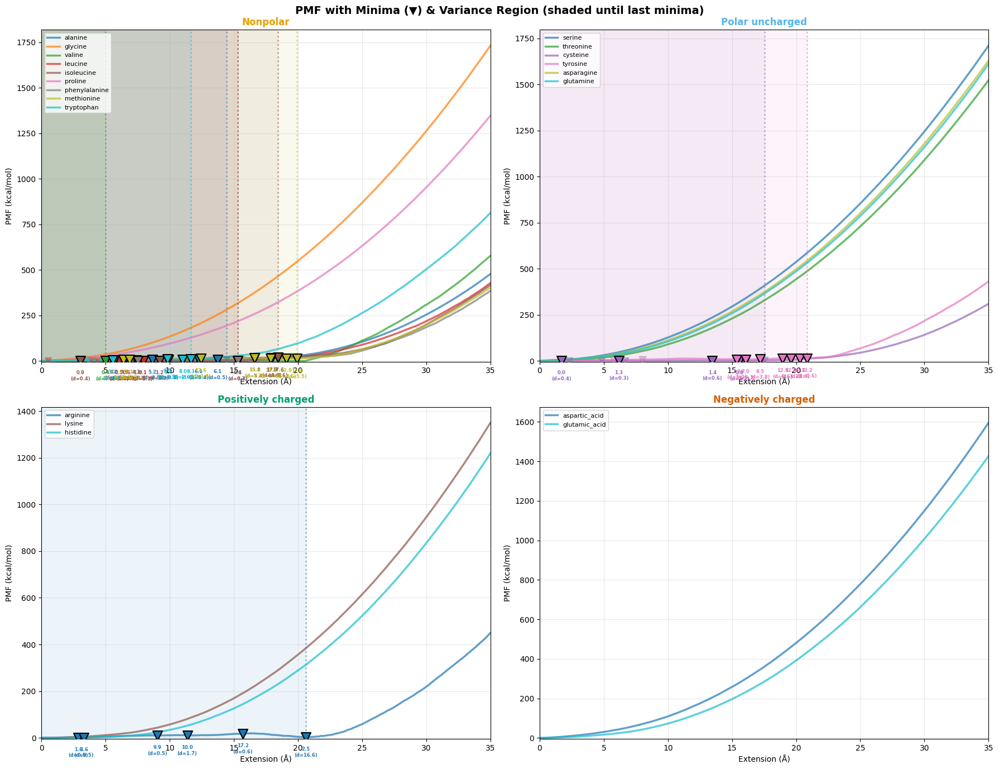

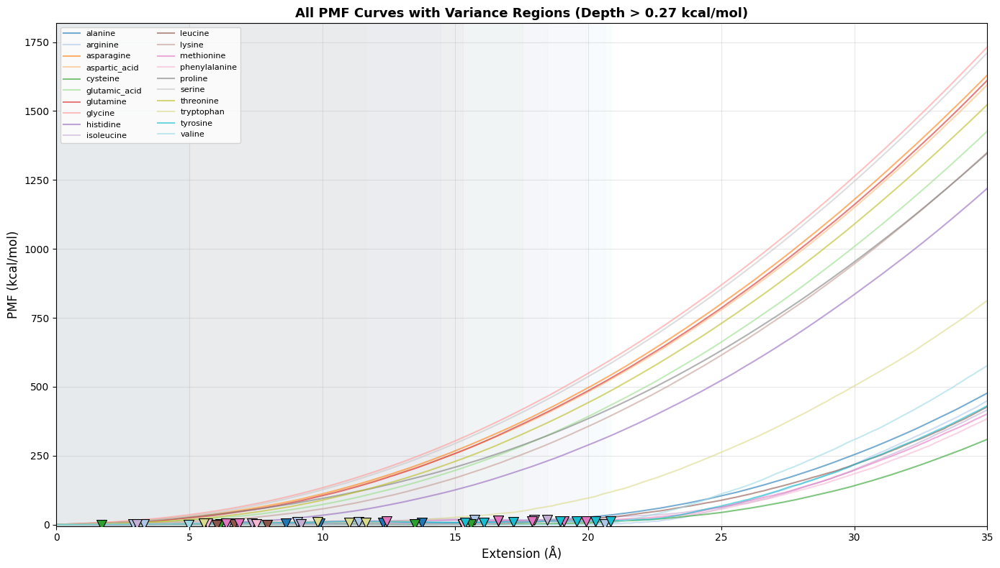


DETAILED ANALYSIS — ALL LOCAL MINIMA WITH VARIANCE METRICS

alanine (Nonpolar):
  Total minima: 6
  Significant minima: 4
  Last minima at: 14.45 Å
  Variance until last minima: 3.8966 kcal²/mol²
  Std dev until last minima: 1.9740 kcal/mol
  Variance after last minima: 19448.7631 kcal²/mol²
  Variance ratio (after/before): 4991.243

  All minima:
    1. Pos=3.16Å, E=1.99kcal/mol, Depth=0.11kcal/mol    -  
    2. Pos=8.63Å, E=5.19kcal/mol, Depth=0.53kcal/mol  ✓ SIG
    3. Pos=9.89Å, E=5.40kcal/mol, Depth=0.39kcal/mol  ✓ SIG
    4. Pos=12.27Å, E=6.14kcal/mol, Depth=0.39kcal/mol  ✓ SIG
    5. Pos=13.75Å, E=6.15kcal/mol, Depth=0.52kcal/mol  ✓ SIG
    6. Pos=14.45Å, E=6.40kcal/mol, Depth=0.27kcal/mol    -  

arginine (Positively charged):
  Total minima: 6
  Significant minima: 6
  Last minima at: 20.62 Å
  Variance until last minima: 28.7023 kcal²/mol²
  Std dev until last minima: 5.3574 kcal/mol
  Variance after last minima: 18452.6720 kcal²/mol²
  Variance ratio (after/before): 642.900

In [109]:
# ============================================================
# LOCAL MINIMA DETECTION — VARIANCE UP TO LAST MINIMA
# ============================================================
from scipy.signal import argrelextrema
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
from scipy.ndimage import gaussian_filter1d

# ── 1. Find all local minima with variance analysis ──
local_minima = {}

for protein in pmf_dict.keys():
    F2 = pmf_dict[protein]
    
    # Find local minima (order=5 means window of 11 points for smoothness)
    minima_idx = argrelextrema(F2, np.less, order=5)[0]
    
    # Get extension positions and energy values at minima
    minima_extensions = c_common[minima_idx]
    minima_energies = F2[minima_idx]
    
    # Calculate depth relative to the PRECEDING PEAK only
    minima_depths = []
    for idx in minima_idx:
        if idx > 0:
            left_peak = F2[:idx].max()
        else:
            left_peak = F2[idx]
        depth = left_peak - F2[idx]
        minima_depths.append(depth)
    
    minima_depths = np.array(minima_depths)
    
    # ── Variance calculation ──
    if len(minima_idx) > 0:
        # If minima exist: variance until last minima
        last_minima_idx = int(minima_idx[-1])
        F2_until_last_minima = F2[:last_minima_idx+1]
        variance_region = F2_until_last_minima
        variance_until_last_minima = float(np.var(variance_region))
        std_until_last_minima = float(np.std(variance_region))
        region_extension = c_common[last_minima_idx]
        region_description = f"until last minima @ {region_extension:.2f} Å"
        has_minima = True
    else:
        # If no minima: variance of entire curve
        variance_until_last_minima = float(np.var(F2))
        std_until_last_minima = float(np.std(F2))
        region_extension = c_common[-1]
        region_description = "entire curve (no minima)"
        has_minima = False
    
    # Variance after last minima (if exists)
    if has_minima and last_minima_idx < len(F2) - 1:
        F2_after_last_minima = F2[last_minima_idx+1:]
        variance_after_last_minima = float(np.var(F2_after_last_minima))
        std_after_last_minima = float(np.std(F2_after_last_minima))
        ratio_after_before = variance_after_last_minima / (variance_until_last_minima + 1e-9)
    else:
        variance_after_last_minima = 0
        std_after_last_minima = 0
        ratio_after_before = 0
    
    local_minima[protein] = {
        'indices': minima_idx,
        'extensions': minima_extensions,
        'energies': minima_energies,
        'depths': minima_depths,
        'n_minima': len(minima_idx),
        'has_minima': has_minima,
        'last_minima_idx': last_minima_idx if has_minima else -1,
        'last_minima_extension': minima_extensions[-1] if has_minima else None,
        'variance_until_last_minima': variance_until_last_minima,
        'std_until_last_minima': std_until_last_minima,
        'variance_after_last_minima': variance_after_last_minima,
        'std_after_last_minima': std_after_last_minima,
        'ratio_after_before': ratio_after_before,
        'region_description': region_description,
    }

# ── 2. Print summary table ──
print("\n" + "="*200)
print("LOCAL MINIMA IN PMF CURVES — WITH VARIANCE ANALYSIS (Until Last Minima)")
print("="*200)
print(f"\n{'Protein':<16} {'Group':<22} {'# Min':<8} {'Last Min (Å)':<14} {'Var Until':<16} {'Var After':<16} {'Ratio':<12} {'Positions':<45}")
print("-" * 200)

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    group = get_group(protein)
    n_min = lm['n_minima']
    
    if n_min > 0:
        pos_str = ', '.join([f"{x:.2f}" for x in lm['extensions']])
        last_min_ext = f"{lm['last_minima_extension']:.2f}"
    else:
        pos_str = "None"
        last_min_ext = "N/A"
    
    print(f"{protein:<16} {group:<22} {n_min:<8} {last_min_ext:<14} "
          f"{lm['variance_until_last_minima']:<16.4f} {lm['variance_after_last_minima']:<16.4f} "
          f"{lm['ratio_after_before']:<12.3f} {pos_str:<45}")

# ── 3. Variance statistics analysis ──
print("\n" + "="*150)
print("VARIANCE STATISTICS (Until Last Minima)")
print("="*150)

var_until = [local_minima[p]['variance_until_last_minima'] for p in local_minima]
std_until = [local_minima[p]['std_until_last_minima'] for p in local_minima]
ratios = [local_minima[p]['ratio_after_before'] for p in local_minima if local_minima[p]['has_minima']]

print(f"\nVariance until last minima:")
print(f"  Mean: {np.mean(var_until):.4f} kcal²/mol²")
print(f"  Std dev: {np.std(var_until):.4f} kcal²/mol²")
print(f"  Min: {np.min(var_until):.4f} kcal²/mol²")
print(f"  Max: {np.max(var_until):.4f} kcal²/mol²")

print(f"\nStd dev until last minima:")
print(f"  Mean: {np.mean(std_until):.4f} kcal/mol")
print(f"  Std dev: {np.std(std_until):.4f} kcal/mol")

if ratios:
    print(f"\nVariance Ratio (After/Before last minima):")
    print(f"  Mean: {np.mean(ratios):.3f}")
    print(f"  Std dev: {np.std(ratios):.3f}")
    print(f"  Min: {np.min(ratios):.3f}")
    print(f"  Max: {np.max(ratios):.3f}")

# ── 4. Depth threshold analysis ──
print("\n" + "="*150)
print("MINIMA DEPTH THRESHOLD ANALYSIS (Relative to Preceding Peak)")
print("="*150)

all_depths = []
for protein in local_minima:
    all_depths.extend(local_minima[protein]['depths'])

if all_depths:
    all_depths = np.array(all_depths)
    depth_threshold = np.percentile(all_depths, 25)
    
    print(f"\nDepth Statistics (all minima across all proteins):")
    print(f"  Mean depth: {np.mean(all_depths):.3f} kcal/mol")
    print(f"  Median depth: {np.median(all_depths):.3f} kcal/mol")
    print(f"  Std dev: {np.std(all_depths):.3f} kcal/mol")
    print(f"  Min depth: {np.min(all_depths):.3f} kcal/mol")
    print(f"  Max depth: {np.max(all_depths):.3f} kcal/mol")
    print(f"  25th percentile: {np.percentile(all_depths, 25):.3f} kcal/mol")
    print(f"  50th percentile: {np.percentile(all_depths, 50):.3f} kcal/mol")
    print(f"  75th percentile: {np.percentile(all_depths, 75):.3f} kcal/mol")
    print(f"\n  Suggested depth threshold (25th percentile): {depth_threshold:.3f} kcal/mol")
else:
    depth_threshold = 0
    print("No minima detected")

# ── 5. Filter minima by depth ──
print("\n" + "="*150)
print("SIGNIFICANT MINIMA (depth > threshold)")
print("="*150)

significant_minima = {}
for protein in local_minima:
    lm = local_minima[protein]
    
    if lm['n_minima'] > 0:
        sig_mask = lm['depths'] > depth_threshold
        sig_idx = lm['indices'][sig_mask]
        sig_ext = lm['extensions'][sig_mask]
        sig_eng = lm['energies'][sig_mask]
        sig_dep = lm['depths'][sig_mask]
    else:
        sig_idx = np.array([])
        sig_ext = np.array([])
        sig_eng = np.array([])
        sig_dep = np.array([])
    
    significant_minima[protein] = {
        'indices': sig_idx,
        'extensions': sig_ext,
        'energies': sig_eng,
        'depths': sig_dep,
        'n_minima': len(sig_idx),
    }

print(f"\n{'Protein':<16} {'Group':<22} {'# Significant':<18} {'Positions (Å)':<45} {'Depths (kcal/mol)':<40}")
print("-" * 150)

for protein in sorted(significant_minima.keys()):
    sm = significant_minima[protein]
    group = get_group(protein)
    n_sig = sm['n_minima']
    
    if n_sig > 0:
        pos_str = ', '.join([f"{x:.2f}" for x in sm['extensions']])
        dep_str = ', '.join([f"{d:.2f}" for d in sm['depths']])
    else:
        pos_str = "None"
        dep_str = "N/A"
    
    print(f"{protein:<16} {group:<22} {n_sig:<18} {pos_str:<45} {dep_str:<40}")

# ── 6. Group-level statistics ──
print("\n" + "="*150)
print("GROUP-LEVEL MINIMA STATISTICS")
print("="*150)

for group_name, members in groups.items():
    valid = [p for p in members if p in local_minima]
    if not valid:
        continue
    
    total_minima = sum([local_minima[p]['n_minima'] for p in valid])
    significant_count = sum([significant_minima[p]['n_minima'] for p in valid])
    proteins_with_minima = [p for p in valid if local_minima[p]['n_minima'] > 0]
    proteins_sig = [p for p in valid if significant_minima[p]['n_minima'] > 0]
    
    group_vars = [local_minima[p]['variance_until_last_minima'] for p in valid]
    group_ratios = [local_minima[p]['ratio_after_before'] for p in valid if local_minima[p]['has_minima']]
    
    print(f"\n{group_name}:")
    print(f"  Members with local minima: {len(proteins_with_minima)}/{len(valid)}")
    print(f"  Members with SIGNIFICANT minima: {len(proteins_sig)}/{len(valid)}")
    print(f"  Total minima (all): {total_minima}")
    print(f"  Total SIGNIFICANT minima: {significant_count}")
    print(f"  Mean # of minima per protein: {np.mean([local_minima[p]['n_minima'] for p in valid]):.2f}")
    print(f"  Mean variance (until last minima): {np.mean(group_vars):.4f} kcal²/mol²")
    if group_ratios:
        print(f"  Mean variance ratio (after/before): {np.mean(group_ratios):.3f}")
    if proteins_sig:
        print(f"  Mean depth of significant minima: {np.mean([d for p in proteins_sig for d in significant_minima[p]['depths']]):.3f} kcal/mol")

# ── 7. Visualize: PMF with minima and variance regions ──
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

for ax_idx, (group_name, members) in enumerate(groups.items()):
    ax = axes[ax_idx]
    cmap = plt.cm.get_cmap('tab10', len(members))
    
    for j, protein in enumerate(members):
        if protein not in pmf_dict:
            continue
        
        F2 = pmf_dict[protein]
        lm = local_minima[protein]
        sm = significant_minima[protein]
        color = cmap(j)
        
        # Plot PMF curve
        ax.plot(c_common, F2, lw=2.5, label=protein, color=color, alpha=0.7)
        
        # Shade region until last minima (variance region)
        if lm['has_minima']:
            last_idx = lm['last_minima_idx']
            ax.axvspan(0, c_common[last_idx], alpha=0.08, color=color, label='_nolegend_')
            ax.axvline(c_common[last_idx], color=color, linestyle=':', alpha=0.5, lw=2)
        
        # Mark ALL local minima (light markers)
        if lm['n_minima'] > 0:
            ax.scatter(lm['extensions'], lm['energies'], 
                      color=color, s=80, marker='v', zorder=4, 
                      edgecolors='gray', linewidth=0.8, alpha=0.5)
        
        # Mark SIGNIFICANT minima (bold markers)
        if sm['n_minima'] > 0:
            ax.scatter(sm['extensions'], sm['energies'], 
                      color=color, s=150, marker='v', zorder=5, 
                      edgecolors='black', linewidth=1.5)
            
            for x, e, d in zip(sm['extensions'], sm['energies'], sm['depths']):
                ax.annotate(f'{e:.1f}\n(d={d:.1f})', xy=(x, e), 
                           textcoords='offset points', xytext=(0, -25),
                           fontsize=6, ha='center', color=color, fontweight='bold')
    
    ax.set_title(f"{group_name}", fontsize=12, fontweight='bold',
                 color=group_colors[group_name])
    ax.set_xlabel("Extension (Å)")
    ax.set_ylabel("PMF (kcal/mol)")
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 35)
    ax.set_ylim(bottom=-5)

plt.suptitle(f"PMF with Minima (▼) & Variance Region (shaded until last minima)", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_minima_variance_regions.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 8. All proteins on single plot with variance regions ──
fig, ax = plt.subplots(figsize=(14, 8))

for protein, color in zip(sorted(pmf_dict.keys()), 
                         plt.cm.tab20(np.linspace(0, 1, len(pmf_dict)))):
    F2 = pmf_dict[protein]
    lm = local_minima[protein]
    sm = significant_minima[protein]
    
    ax.plot(c_common, F2, lw=1.5, label=protein, color=color, alpha=0.6)
    
    # Shade variance region
    if lm['has_minima']:
        last_idx = lm['last_minima_idx']
        ax.axvspan(0, c_common[last_idx], alpha=0.02, color=color)
    
    # Mark significant minima
    if sm['n_minima'] > 0:
        ax.scatter(sm['extensions'], sm['energies'], 
                  color=color, s=100, marker='v', zorder=4, edgecolors='black', linewidth=0.8)

ax.set_xlabel("Extension (Å)", fontsize=12)
ax.set_ylabel("PMF (kcal/mol)", fontsize=12)
ax.set_title(f"All PMF Curves with Variance Regions (Depth > {depth_threshold:.2f} kcal/mol)", 
             fontsize=13, fontweight='bold')
ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.grid(alpha=0.3)
ax.set_xlim(0, 35)
ax.set_ylim(bottom=-5)
plt.tight_layout()
plt.savefig(f"{base_dir}/pmf_all_with_variance_regions.png", dpi=150, bbox_inches='tight')
plt.show()

# ── 9. Detailed minima analysis table ──
print("\n" + "="*180)
print("DETAILED ANALYSIS — ALL LOCAL MINIMA WITH VARIANCE METRICS")
print("="*180)

minima_data = []

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    sm = significant_minima[protein]
    
    print(f"\n{protein} ({get_group(protein)}):")
    print(f"  Total minima: {lm['n_minima']}")
    print(f"  Significant minima: {sm['n_minima']}")
    
    if lm['has_minima']:
        print(f"  Last minima at: {lm['last_minima_extension']:.2f} Å")
        print(f"  Variance until last minima: {lm['variance_until_last_minima']:.4f} kcal²/mol²")
        print(f"  Std dev until last minima: {lm['std_until_last_minima']:.4f} kcal/mol")
        if lm['variance_after_last_minima'] > 0:
            print(f"  Variance after last minima: {lm['variance_after_last_minima']:.4f} kcal²/mol²")
            print(f"  Variance ratio (after/before): {lm['ratio_after_before']:.3f}")
    else:
        print(f"  No minima found (entire curve variance): {lm['variance_until_last_minima']:.4f} kcal²/mol²")
    
    # List all minima
    if lm['n_minima'] > 0:
        print(f"\n  All minima:")
        for i, (ext, eng, dep) in enumerate(zip(lm['extensions'], lm['energies'], lm['depths']), 1):
            is_sig = "✓ SIG" if ext in sm['extensions'] else "  -  "
            print(f"    {i}. Pos={ext:.2f}Å, E={eng:.2f}kcal/mol, Depth={dep:.2f}kcal/mol  {is_sig}")

# ── 10. Summary classification table ──
print("\n" + "="*150)
print("MINIMA VALIDITY ASSESSMENT")
print("="*150)
print(f"\n{'Protein':<16} {'Group':<22} {'# Min':<8} {'# Sig':<8} {'Var Ratio':<14} {'Assessment':<40}")
print("-" * 150)

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    sm = significant_minima[protein]
    group = get_group(protein)
    
    if not lm['has_minima']:
        assessment = "No minima (smooth curve)"
        var_ratio_str = "N/A"
    elif lm['ratio_after_before'] > 3:
        assessment = "✓ Valid: Sharp rise after minima"
        var_ratio_str = f"{lm['ratio_after_before']:.2f}"
    elif lm['ratio_after_before'] > 1.5:
        assessment = "✓ Likely valid: Moderate rise"
        var_ratio_str = f"{lm['ratio_after_before']:.2f}"
    elif lm['ratio_after_before'] > 1:
        assessment = "⚠ Marginal: Slight rise"
        var_ratio_str = f"{lm['ratio_after_before']:.2f}"
    else:
        assessment = "✗ Questionable: No clear rise"
        var_ratio_str = f"{lm['ratio_after_before']:.2f}"
    
    print(f"{protein:<16} {group:<22} {lm['n_minima']:<8} {sm['n_minima']:<8} {var_ratio_str:<14} {assessment:<40}")

print("\n✓ Minima and variance analysis complete!")

In [110]:
# ============================================================
# MINIMA DEPTH vs AMINO ACID VARIANCE COMPARISON TABLE
# ============================================================

print("\n" + "="*180)
print("MINIMA DEPTH vs AMINO ACID VARIANCE COMPARISON")
print("="*180)

# Create comprehensive comparison table
comparison_data = []

for protein in sorted(local_minima.keys()):
    lm = local_minima[protein]
    group = get_group(protein)
    
    # Get the std dev until last minima for this protein
    aa_std_dev = lm['std_until_last_minima']
    
    # For each minima in this protein
    if lm['n_minima'] > 0:
        for i, (ext, eng, dep) in enumerate(zip(lm['extensions'], lm['energies'], lm['depths']), 1):
            # Check if this minima is significant
            is_significant = ext in significant_minima[protein]['extensions']
            sig_marker = "✓ SIG" if is_significant else "     "
            
            # Ratio of depth to AA std dev
            depth_to_std_ratio = dep / (aa_std_dev + 1e-9)
            
            comparison_data.append({
                'Protein': protein,
                'Group': group,
                'Min #': i,
                'Position (Å)': f"{ext:.2f}",
                'Minima Depth (kcal/mol)': f"{dep:.4f}",
                'AA Std Dev (kcal/mol)': f"{aa_std_dev:.4f}",
                'Depth/StdDev Ratio': f"{depth_to_std_ratio:.3f}",
                'Significant': sig_marker,
            })
    else:
        # For proteins with no minima, still include the AA std dev info
        comparison_data.append({
            'Protein': protein,
            'Group': group,
            'Min #': 'N/A',
            'Position (Å)': 'N/A',
            'Minima Depth (kcal/mol)': 'N/A',
            'AA Std Dev (kcal/mol)': f"{aa_std_dev:.4f}",
            'Depth/StdDev Ratio': 'N/A',
            'Significant': 'N/A',
        })

# Create DataFrame and print
import pandas as pd
df_comparison = pd.DataFrame(comparison_data)
print("\nDetailed Minima Depth vs Amino Acid Variance:")
print(df_comparison.to_string(index=False))

# Summary statistics by group
print("\n" + "="*180)
print("SUMMARY STATISTICS BY GROUP")
print("="*180)

for group_name in sorted(groups.keys()):
    group_data = df_comparison[df_comparison['Group'] == group_name]
    
    # Filter out N/A rows for statistics
    valid_ratios = []
    valid_depths = []
    valid_stds = []
    
    for idx, row in group_data.iterrows():
        if row['Depth/StdDev Ratio'] != 'N/A':
            valid_ratios.append(float(row['Depth/StdDev Ratio']))
            valid_depths.append(float(row['Minima Depth (kcal/mol)']))
            valid_stds.append(float(row['AA Std Dev (kcal/mol)']))
    
    print(f"\n{group_name}:")
    print(f"  Number of minima: {len(valid_ratios)}")
    
    if valid_ratios:
        print(f"  Depth/StdDev Ratio:")
        print(f"    Mean: {np.mean(valid_ratios):.3f}")
        print(f"    Min: {np.min(valid_ratios):.3f}")
        print(f"    Max: {np.max(valid_ratios):.3f}")
        print(f"    Std Dev: {np.std(valid_ratios):.3f}")
        
        print(f"  Minima Depths:")
        print(f"    Mean: {np.mean(valid_depths):.4f} kcal/mol")
        print(f"    Range: {np.min(valid_depths):.4f} - {np.max(valid_depths):.4f} kcal/mol")
        
        print(f"  AA Variance (Std Dev until last minima):")
        print(f"    Mean: {np.mean(valid_stds):.4f} kcal/mol")
        print(f"    Range: {np.min(valid_stds):.4f} - {np.max(valid_stds):.4f} kcal/mol")
    else:
        print(f"  No minima with depth data")

# Overall statistics
print("\n" + "="*180)
print("OVERALL STATISTICS")
print("="*180)

all_ratios = [float(x) for x in df_comparison['Depth/StdDev Ratio'] if x != 'N/A']
all_depths = [float(x) for x in df_comparison['Minima Depth (kcal/mol)'] if x != 'N/A']
all_stds = [float(x) for x in df_comparison['AA Std Dev (kcal/mol)'] if x != 'N/A']

print(f"\nDepth/StdDev Ratio across all minima:")
print(f"  Mean: {np.mean(all_ratios):.3f}")
print(f"  Median: {np.median(all_ratios):.3f}")
print(f"  Min: {np.min(all_ratios):.3f}")
print(f"  Max: {np.max(all_ratios):.3f}")
print(f"  Std Dev: {np.std(all_ratios):.3f}")

print(f"\nMinima Depths across all proteins:")
print(f"  Mean: {np.mean(all_depths):.4f} kcal/mol")
print(f"  Median: {np.median(all_depths):.4f} kcal/mol")
print(f"  Range: {np.min(all_depths):.4f} - {np.max(all_depths):.4f} kcal/mol")

print(f"\nAA Variance (Std Dev until last minima) across all proteins:")
print(f"  Mean: {np.mean(all_stds):.4f} kcal/mol")
print(f"  Median: {np.median(all_stds):.4f} kcal/mol")
print(f"  Range: {np.min(all_stds):.4f} - {np.max(all_stds):.4f} kcal/mol")

# Interpretation guide
print("\n" + "="*180)
print("INTERPRETATION GUIDE")
print("="*180)
print(f"\nDepth/StdDev Ratio meanings:")
print(f"  Ratio > 2.0:   Minima depth is significantly larger than AA variance (strong minima)")
print(f"  Ratio 1.0-2.0: Minima depth is comparable to AA variance (moderate minima)")
print(f"  Ratio < 1.0:   Minima depth is smaller than AA variance (weak/noisy minima)")

print("\n✓ Minima depth vs AA variance comparison complete!")


MINIMA DEPTH vs AMINO ACID VARIANCE COMPARISON

Detailed Minima Depth vs Amino Acid Variance:
      Protein              Group Min # Position (Å) Minima Depth (kcal/mol) AA Std Dev (kcal/mol) Depth/StdDev Ratio Significant
      alanine           Nonpolar     1         3.16                  0.1087                1.9740              0.055            
      alanine           Nonpolar     2         8.63                  0.5307                1.9740              0.269       ✓ SIG
      alanine           Nonpolar     3         9.89                  0.3857                1.9740              0.195       ✓ SIG
      alanine           Nonpolar     4        12.27                  0.3937                1.9740              0.199       ✓ SIG
      alanine           Nonpolar     5        13.75                  0.5227                1.9740              0.265       ✓ SIG
      alanine           Nonpolar     6        14.45                  0.2738                1.9740              0.139            
  